# Проект: сегментация клиентов и прогноз риска задержки доставки (CargaPronto)

<small>Автор: strmcrown // Дата: 07.10.2026</small>

**Заказчик:** CargaPronto — крупнейший логистический оператор, связывающий производственные хабы Пуэрто-Рико с потребителями в США.

**Проблема:** 55% заказов доставляются с задержкой; штрафы за нарушение SLA превысили бюджет на IT-развитие.

**Гипотеза транспортного департамента:** задержки вызваны не сбоями в логистике, а специфическим профилем клиентов («чёрные дыры» на карте, частые возвраты и т.д.).

**Цель:** методами обучения без учителя сегментировать базу клиентов (геозоны + поведенческие профили), проверить гипотезу и построить модель бинарной классификации, которая в момент оформления заказа оценивает риск задержки. Метрика ROC-AUC, целевое значение — **> 0.75**.

**Инструменты:** LogisticRegression, CatBoostClassifier, K-Means++, t-SNE, GroupShuffleSplit.

**План работы:** загрузка и аудит данных → EDA → разделение на выборки (60:20:20, GroupShuffleSplit) → базовые модели → геокластеризация → RFM-кластеризация → модели на новых признаках → подбор K → тестирование → выводы и рекомендации.

## Импорт библиотек, выполнение базовых настроек

Загружаем все необходимые для выполнения проекта библиотеки и компоненты, фиксируем `RANDOM_STATE` для воспроизводимости, выполняем базовые настройки графиков и pandas.

In [ ]:
%matplotlib inline

import os
import sys
import subprocess
import platform
import warnings
import importlib.metadata as importlib_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from phik import phik_matrix

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

from catboost import CatBoostClassifier

import joblib

RANDOM_STATE = 42
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.4f}'.format)
sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print(f'Python {sys.version.split()[0]} | random_state = {RANDOM_STATE}')

Python 3.13.0 | random_state = 42


In [ ]:
# Сохранение библиотек и версий окружения
KEY_LIBS = ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn',
            'catboost', 'phik', 'joblib', 'scipy', 'nbformat']

rows = [{'library': 'python', 'version': platform.python_version(), 'platform': platform.platform()}]
for lib in KEY_LIBS:
    try:
        rows.append({'library': lib, 'version': importlib_metadata.version(lib), 'platform': ''})
    except importlib_metadata.PackageNotFoundError:
        rows.append({'library': lib, 'version': 'not installed', 'platform': ''})

df_versions = pd.DataFrame(rows)
display(df_versions)

df_versions.to_csv('library_versions.txt', sep='\t', index=False)

with open('requirements_freeze.txt', 'w', encoding='utf-8') as f:
    subprocess.run([sys.executable, '-m', 'pip', 'freeze'], stdout=f, check=False)

print('Сохранено: library_versions.txt, requirements_freeze.txt')

,library,version,platform
0,python,3.13.0,Windows-11-10.0.26200-SP0
1,numpy,2.5.3,
2,pandas,2.3.3,
3,matplotlib,3.11.1,
4,seaborn,0.13.2,
5,scikit-learn,1.9.0,
6,catboost,1.2.10,
7,phik,0.12.5,
8,joblib,1.5.3,
9,scipy,1.18.0,


Сохранено: library_versions.txt, requirements_freeze.txt


## Загрузка данных, первичное знакомство

- Загружаем датасеты `ds_s18_customers.csv` и `ds_s18_orders.csv` (локальный путь+платформа практикума).
- Проводим технический аудит данных: типы, пропуски, статистики.
- Выявляем и устраняем полные дубликаты строк (в логистических данных — признак сбоя выгрузки, искусственно завышающий метрики задержек).
- Выполняем проверку целостности данных (ID-Check): каждый заказ должен иметь профиль клиента.
- Подготовим признаки даты и времени: `order_date` → `datetime`, добавим `order_month`, `order_weekday`, `order_hour`.

In [ ]:
def resolve_path(filename):
    candidates = [
        os.path.join('/datasets', filename),
        os.path.join('datasets', filename),
        os.path.join('.', filename),
        os.path.join(r'C:\AI\ya_DS\sprint18', filename),
    ]
    for candidate in candidates:
        if os.path.exists(candidate):
            return candidate
    raise FileNotFoundError(f'Файл {filename} не найден в {candidates}')

PATH_CUSTOMERS = resolve_path('ds_s18_customers.csv')
PATH_ORDERS = resolve_path('ds_s18_orders.csv')

df_customers = pd.read_csv(PATH_CUSTOMERS)
df_orders = pd.read_csv(PATH_ORDERS)

print(f'df_customers: {df_customers.shape[0]} строк, {df_customers.shape[1]} колонок -> {PATH_CUSTOMERS}')
print(f'df_orders:    {df_orders.shape[0]} строк, {df_orders.shape[1]} колонок -> {PATH_ORDERS}')
display(df_customers.head())
display(df_orders.head())

df_customers: 20652 строк, 8 колонок -> C:\AI\ya_DS\sprint18\ds_s18_customers.csv
df_orders:    180519 строк, 7 колонок -> C:\AI\ya_DS\sprint18\ds_s18_orders.csv


,customer_id,customer_lat,customer_lon,total_sales,total_orders,avg_discount,return_rate,recency
0,1,25.9536,-97.5077,472.4500,1,0.0600,0.0000,793
1,2,38.3756,-104.7260,1618.6600,4,0.1260,0.0000,137
2,3,18.0254,-66.6151,3189.2000,5,0.1050,0.0000,230
3,4,33.6700,-112.2471,1480.7100,4,0.1350,0.0000,381
4,5,18.3591,-66.0779,1101.9200,3,0.1400,0.0000,458


,order_id,customer_id,late_delivery_risk,shipping_mode,category_name,order_date,item_price
0,180517,20755,0,Standard Class,Sporting Goods,2018-01-31 22:56:00,327.7500
1,179254,19492,1,Standard Class,Sporting Goods,2018-01-13 12:27:00,327.7500
2,179253,19491,0,Standard Class,Sporting Goods,2018-01-13 12:06:00,327.7500
3,179252,19490,0,Standard Class,Sporting Goods,2018-01-13 11:45:00,327.7500
4,179251,19489,0,Standard Class,Sporting Goods,2018-01-13 11:24:00,327.7500


In [ ]:
# Технический аудит: типы данных, пропуски, базовые статистики
for name, df in [('df_customers', df_customers), ('df_orders', df_orders)]:
    print(f'=== {name} ===')
    print(df.dtypes.to_string())
    print(f'Пропусков всего: {int(df.isna().sum().sum())}')
    print(f'Полных дубликатов строк: {int(df.duplicated().sum())}')
    display(df.describe(include='all').T)

=== df_customers ===
customer_id       int64
customer_lat    float64
customer_lon    float64
total_sales     float64
total_orders      int64
avg_discount    float64
return_rate     float64
recency           int64
Пропусков всего: 0
Полных дубликатов строк: 0


,count,mean,std,min,25%,50%,75%,max
customer_id,20652.0000,10400.2859,5993.1062,1.0000,5208.7500,10407.5000,15594.2500,20757.0000
customer_lat,20652.0000,29.7487,9.8241,-33.9376,18.2661,33.2164,39.2922,48.7819
customer_lon,20652.0000,-84.9501,21.2539,-158.0260,-98.4693,-76.7596,-66.3706,115.2631
total_sales,20652.0000,1600.5424,1508.4180,8.4700,254.9400,1294.5050,2621.1400,9436.6101
total_orders,20652.0000,3.1838,2.4307,1.0000,1.0000,3.0000,5.0000,15.0000
avg_discount,20652.0000,0.1017,0.0483,0.0000,0.0762,0.1000,0.1230,0.2500
return_rate,20652.0000,0.0430,0.1566,0.0000,0.0000,0.0000,0.0000,1.0000
recency,20652.0000,221.0891,199.3954,1.0000,76.0000,160.0000,308.0000,1126.0000


=== df_orders ===
order_id                int64
customer_id             int64
late_delivery_risk      int64
shipping_mode          object
category_name          object
order_date             object
item_price            float64
Пропусков всего: 0
Полных дубликатов строк: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,180519.0000,NaN,NaN,NaN,90260.0000,52111.4910,1.0000,45130.5000,90260.0000,135389.5000,180519.0000
customer_id,180519.0000,NaN,NaN,NaN,6691.3795,4162.9181,1.0000,3258.5000,6457.0000,9779.0000,20757.0000
late_delivery_risk,180519.0000,NaN,NaN,NaN,0.5483,0.4977,0.0000,0.0000,1.0000,1.0000,1.0000
shipping_mode,180519,4,Standard Class,107752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category_name,180519,50,Cleats,24551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,180519,65752,2017-01-04 02:28:00,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
item_price,180519.0000,NaN,NaN,NaN,141.2325,139.7325,9.9900,50.0000,59.9900,199.9900,1999.9900


In [ ]:
# Устранение полных дубликатов строк
dup_customers = int(df_customers.duplicated().sum())
dup_orders = int(df_orders.duplicated().sum())
if dup_customers:
    df_customers = df_customers.drop_duplicates().reset_index(drop=True)
if dup_orders:
    df_orders = df_orders.drop_duplicates().reset_index(drop=True)
print(f'Удалено дубликатов: customers={dup_customers}, orders={dup_orders}')
print(f'Итоговые размеры: customers={df_customers.shape}, orders={df_orders.shape}')

Удалено дубликатов: customers=0, orders=0
Итоговые размеры: customers=(20652, 8), orders=(180519, 7)


In [ ]:
# Проверка целостности связей (ID-Check)
customers_ids = set(df_customers['customer_id'])
orders_ids = set(df_orders['customer_id'])

orphan_orders = orders_ids - customers_ids          # заказы без профиля клиента
customers_wo_orders = customers_ids - orders_ids    # клиенты без заказов

print(f'Заказы-сироты (customer_id отсутствует в справочнике): {len(orphan_orders)}')
print(f'Клиенты без заказов: {len(customers_wo_orders)}')
print(f'Дубликаты order_id: {int(df_orders["order_id"].duplicated().sum())}')
print(f'Уникальных клиентов в заказах: {df_orders["customer_id"].nunique()} из {len(df_customers)} профилей')

assert len(orphan_orders) == 0, 'Есть заказы-сироты: профилирование клиентов для них невозможно'
print('ID-Check пройден: связи клиентов и заказов целостны.')

Заказы-сироты (customer_id отсутствует в справочнике): 0
Клиенты без заказов: 0
Дубликаты order_id: 0
Уникальных клиентов в заказах: 20652 из 20652 профилей
ID-Check пройден: связи клиентов и заказов целостны.


In [ ]:
# Признаки даты и времени
df_orders['order_date'] = pd.to_datetime(df_orders['order_date'])
df_orders['order_month'] = df_orders['order_date'].dt.month
df_orders['order_weekday'] = df_orders['order_date'].dt.weekday
df_orders['order_hour'] = df_orders['order_date'].dt.hour

print('Диапазон дат заказов:', df_orders['order_date'].min(), '—', df_orders['order_date'].max())
display(df_orders[['order_id', 'order_date', 'order_month', 'order_weekday', 'order_hour']].head())

Диапазон дат заказов: 2015-01-01 00:00:00 — 2018-01-31 23:38:00


,order_id,order_date,order_month,order_weekday,order_hour
0,180517,2018-01-31 22:56:00,1,2,22
1,179254,2018-01-13 12:27:00,1,5,12
2,179253,2018-01-13 12:06:00,1,5,12
3,179252,2018-01-13 11:45:00,1,5,11
4,179251,2018-01-13 11:24:00,1,5,11


## EDA

Цель: исследовать структуру данных и подтвердить гипотезы транспортного департамента о «неоднородности» базы. Кроме того, изучаем и удаляем географические аномалии.

- Проверяем баланс классов `late_delivery_risk` (аудит заявлял 55% задержек).
- Выполняем географический аудит: `customer_lat` / `customer_lon` на диаграмме рассеяния.
- Удаляем аномалии: выбросы по `customer_lon` за пределами −125…−20 — «цифровой шум» (GPS-ошибки, дефолтные значения). KMeans чувствителен к выбросам: одна точка в другом полушарии «увозит» центроиды. Если удаляем профиль клиента — удаляем и все его заказы.
- Анализируем зависимости признаков с целью (матрица корреляций φk / `phik`, корректно работает с категориальными данными).

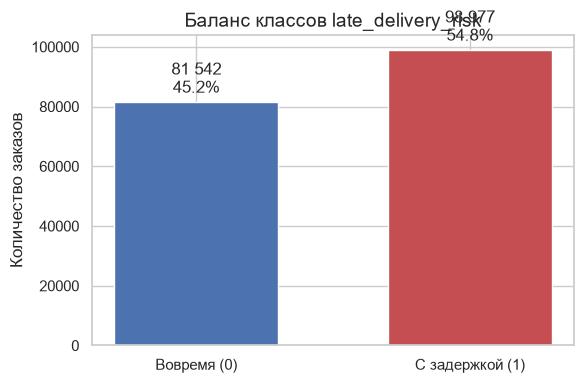

Доля заказов с задержкой: 54.83% — информация внутреннего аудита о 55% опозданий подтверждается.


In [ ]:
# Баланс целевой переменной
balance = df_orders['late_delivery_risk'].value_counts().sort_index()
share = df_orders['late_delivery_risk'].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Вовремя (0)', 'С задержкой (1)'], balance.values, color=['#4c72b0', '#c44e52'], width=0.6)
for bar, cnt, shr in zip(bars, balance.values, share.values):
    ax.text(bar.get_x() + bar.get_width() / 2, cnt + 1500, f'{cnt:,}\n{shr:.1%}'.replace(',', ' '),
            ha='center', va='bottom')
ax.set_title('Баланс классов late_delivery_risk')
ax.set_ylabel('Количество заказов')
plt.tight_layout()
plt.show()

print(f'Доля заказов с задержкой: {share[1]:.2%} — информация внутреннего аудита о 55% опозданий подтверждается.')

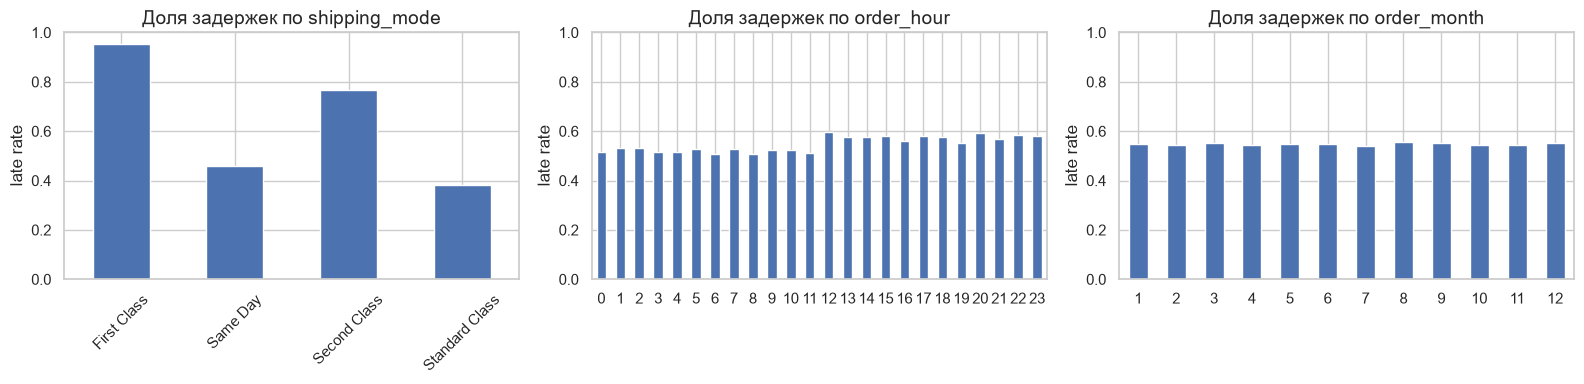

Доля задержек по категориям топ-10:
                      late_rate  orders
category_name                          
Cleats                   0.5497   24551
Men's Footwear           0.5449   22246
Women's Apparel          0.5456   21035
Indoor/Outdoor Games     0.5475   19298
Fishing                  0.5493   17325
Water Sports             0.5481   15540
Camping & Hiking         0.5453   13729
Cardio Equipment         0.5450   12487
Shop By Sport            0.5515   10984
Electronics              0.5608    3156


In [ ]:
# Доля задержек по режимам доставки и по времени заказа
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, rot in zip(axes, ['shipping_mode', 'order_hour', 'order_month'], [45, 0, 0]):
    rate = df_orders.groupby(col)['late_delivery_risk'].mean()
    rate.plot(kind='bar', ax=ax, color='#4c72b0', rot=rot)
    ax.set_title(f'Доля задержек по {col}')
    ax.set_ylabel('late rate')
    ax.set_xlabel('')
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

print('Доля задержек по категориям топ-10:')
print(df_orders.groupby('category_name')['late_delivery_risk'].agg(['mean', 'size'])
      .sort_values('size', ascending=False).head(10).rename(columns={'mean': 'late_rate', 'size': 'orders'}))

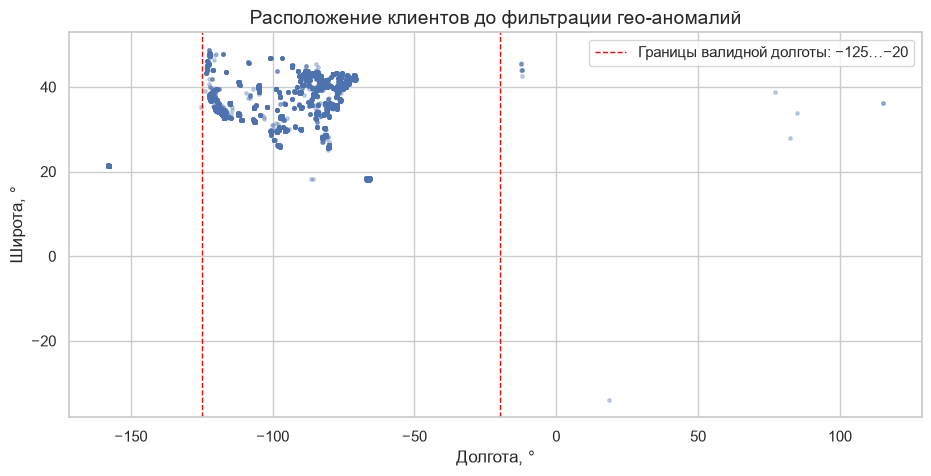

Диапазон долгот до фильтрации: [-158.03; 115.26]
Диапазон широт до фильтрации:  [-33.94; 48.78]
Значения за пределами −125…−20 — GPS-шум (ошибки приборов/дефолты), а не реальные адреса.


In [ ]:
# Географический аудит до фильтрации
fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(df_customers['customer_lon'], df_customers['customer_lat'], s=6, alpha=0.3, color='#4c72b0')
ax.axvline(-125, color='red', ls='--', lw=1)
ax.axvline(-20, color='red', ls='--', lw=1, label='Границы валидной долготы: −125…−20')
ax.set_xlabel('Долгота, °')
ax.set_ylabel('Широта, °')
ax.set_title('Расположение клиентов до фильтрации гео-аномалий')
ax.legend()
plt.show()

print(f'Диапазон долгот до фильтрации: [{df_customers["customer_lon"].min():.2f}; {df_customers["customer_lon"].max():.2f}]')
print(f'Диапазон широт до фильтрации:  [{df_customers["customer_lat"].min():.2f}; {df_customers["customer_lat"].max():.2f}]')
print('Значения за пределами −125…−20 — GPS-шум (ошибки приборов/дефолты), а не реальные адреса.')

Удалено клиентов-аномалий: 156
Удалено связанных заказов: 1430 (целостность связей сохранена)
Осталось: 20496 клиентов, 179089 заказов
Диапазон долгот после фильтрации: [-123.72; -65.83]


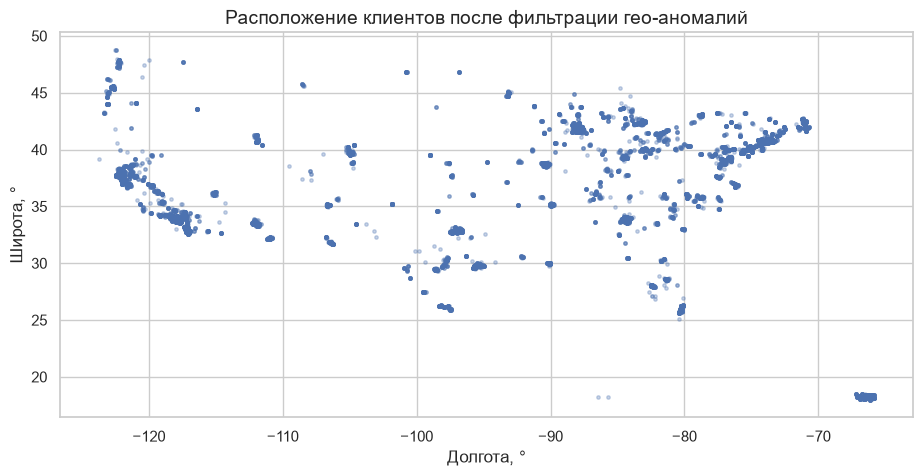

In [ ]:
# Удаление географических аномалий (customer_lon вне диапазона −125…−20)
LON_MIN, LON_MAX = -125, -20
geo_bad = (df_customers['customer_lon'] < LON_MIN) | (df_customers['customer_lon'] > LON_MAX)

n_bad_customers = int(geo_bad.sum())
bad_customer_ids = set(df_customers.loc[geo_bad, 'customer_id'])

df_customers = df_customers[~geo_bad].copy()

orders_before = len(df_orders)
df_orders = df_orders[df_orders['customer_id'].isin(set(df_customers['customer_id']))].copy()
n_removed_orders = orders_before - len(df_orders)

print(f'Удалено клиентов-аномалий: {n_bad_customers}')
print(f'Удалено связанных заказов: {n_removed_orders} (целостность связей сохранена)')
print(f'Осталось: {df_customers.shape[0]} клиентов, {df_orders.shape[0]} заказов')
print(f'Диапазон долгот после фильтрации: [{df_customers["customer_lon"].min():.2f}; {df_customers["customer_lon"].max():.2f}]')

fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(df_customers['customer_lon'], df_customers['customer_lat'], s=6, alpha=0.3, color='#4c72b0')
ax.set_xlabel('Долгота, °')
ax.set_ylabel('Широта, °')
ax.set_title('Расположение клиентов после фильтрации гео-аномалий')
plt.show()

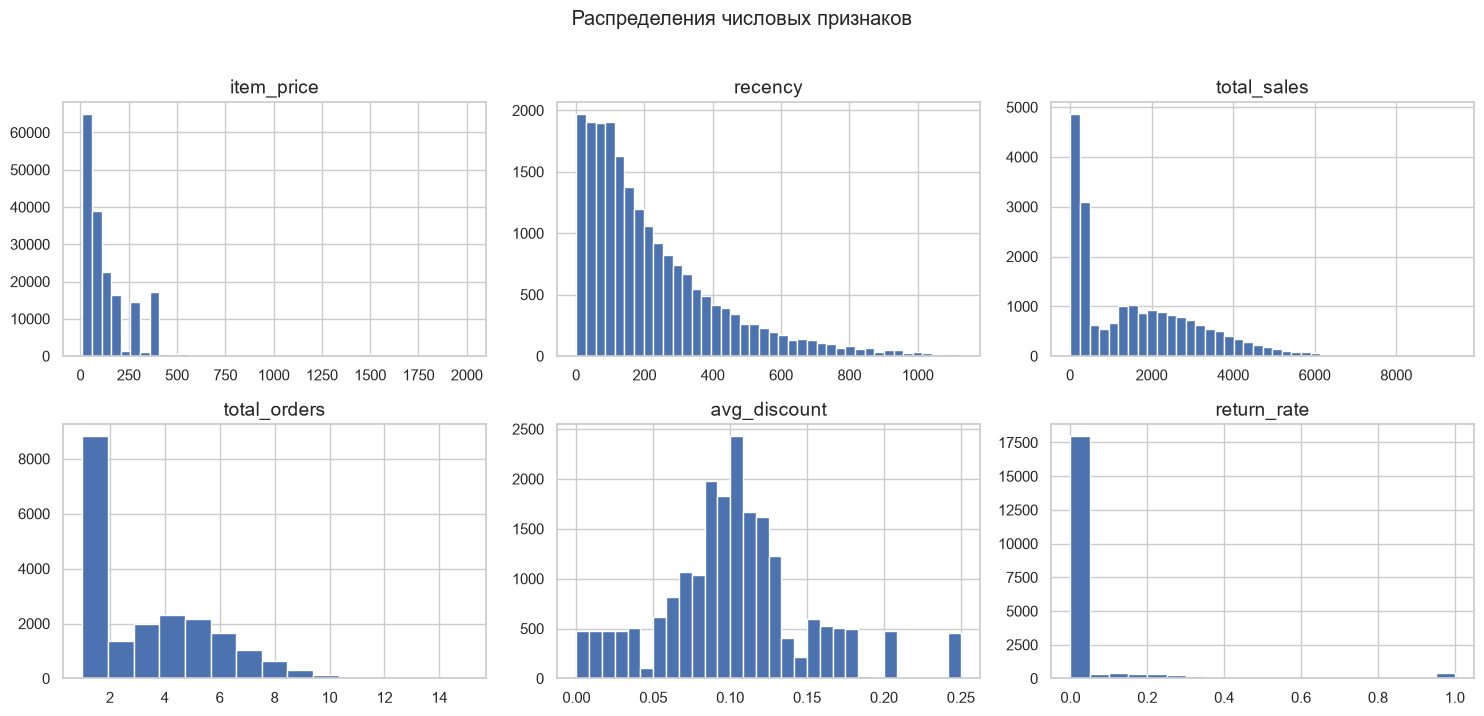

In [ ]:
# Распределения ключевых числовых признаков
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
hist_specs = [
    ('item_price', df_orders, 40),
    ('recency', df_customers, 40),
    ('total_sales', df_customers, 40),
    ('total_orders', df_customers, 15),
    ('avg_discount', df_customers, 30),
    ('return_rate', df_customers, 20),
]
for ax, (col, src, bins) in zip(axes.ravel(), hist_specs):
    ax.hist(src[col], bins=bins, color='#4c72b0', edgecolor='white')
    ax.set_title(col)
fig.suptitle('Распределения числовых признаков', y=1.02)
plt.tight_layout()
plt.show()

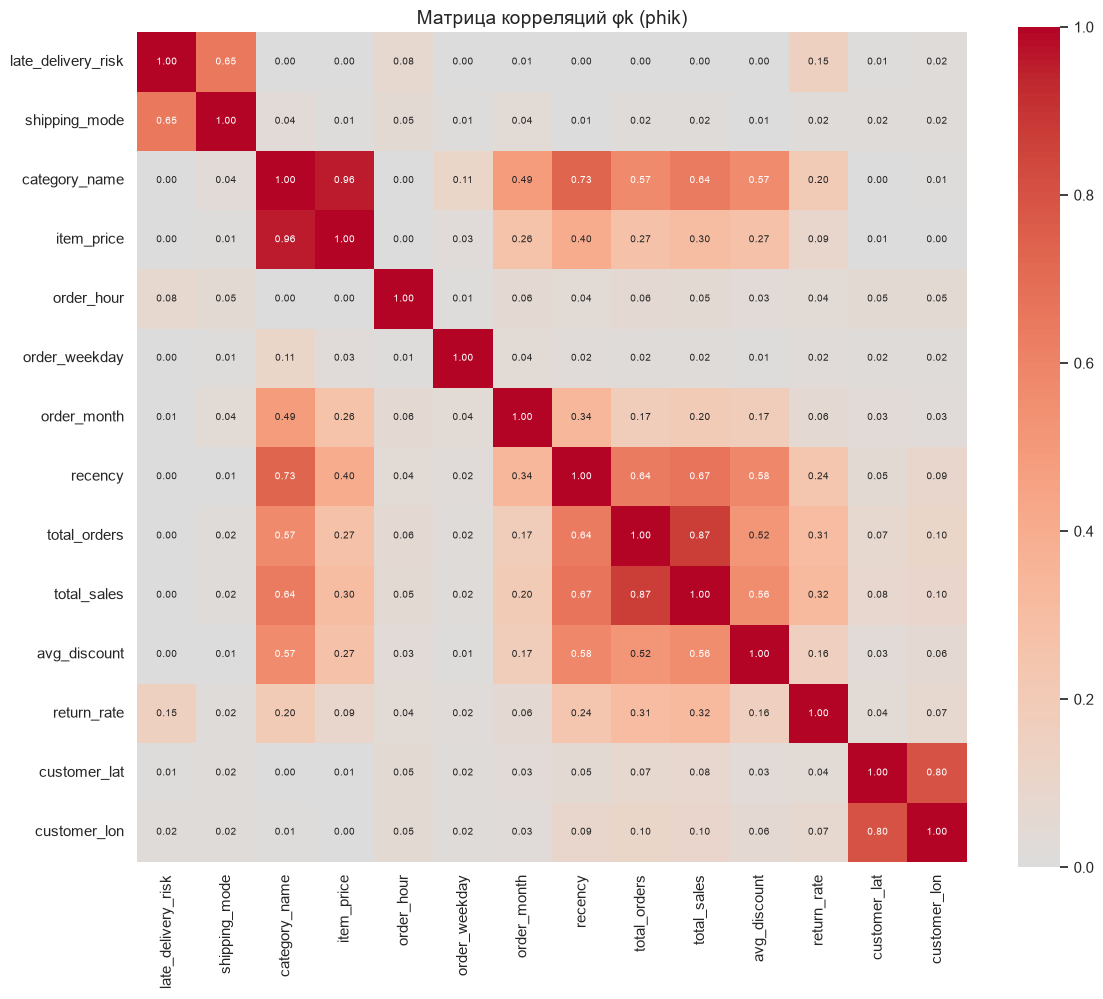

In [ ]:
# Корреляционный анализ: матрица phik (φk) — работает с категориальными данными
df_merged = df_orders.merge(df_customers, on='customer_id', how='left')

PHIK_COLS = ['late_delivery_risk', 'shipping_mode', 'category_name', 'item_price',
             'order_hour', 'order_weekday', 'order_month',
             'recency', 'total_orders', 'total_sales', 'avg_discount', 'return_rate',
             'customer_lat', 'customer_lon']
INTERVAL_COLS = ['item_price', 'recency', 'total_orders', 'total_sales',
                 'avg_discount', 'return_rate', 'customer_lat', 'customer_lon']

phik_corr = phik_matrix(df_merged[PHIK_COLS], interval_cols=INTERVAL_COLS, verbose=False)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(phik_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, annot_kws={'fontsize': 7}, ax=ax)
ax.set_title('Матрица корреляций φk (phik)')
plt.tight_layout()
plt.show()

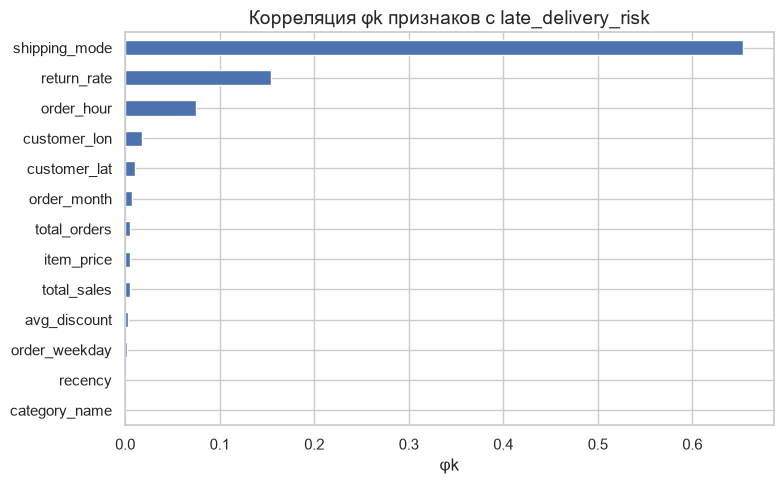

Топ признаков по связи с задержкой:
shipping_mode   0.6537
return_rate     0.1543
order_hour      0.0752
customer_lon    0.0174
customer_lat    0.0103
order_month     0.0073
total_orders    0.0049
item_price      0.0048
total_sales     0.0047
avg_discount    0.0030
order_weekday   0.0017
recency         0.0000
category_name   0.0000


In [ ]:
# Связь признаков с целевой переменной
target_corr = (phik_corr['late_delivery_risk']
               .drop('late_delivery_risk')
               .sort_values(ascending=True))

fig, ax = plt.subplots(figsize=(8, 5))
target_corr.plot(kind='barh', ax=ax, color='#4c72b0')
ax.set_title('Корреляция φk признаков с late_delivery_risk')
ax.set_xlabel('φk')
plt.tight_layout()
plt.show()

print('Топ признаков по связи с задержкой:')
print(target_corr.sort_values(ascending=False).to_string())

**ВЫВОДЫ EDA:**
1. Доля задержек = 54.83%: информация аудита о 55% опозданий подтверждается, классы сбалансированы.
2. База клиентов неоднородна: выделены очаги в Пуэрто-Рико, на Западе, Северо-Востоке и Юге США; 
   географические «цифровые шумы» (156 клиентов) отфильтрованы вместе с их заказами.
3. Сильнейшая связь с задержкой — у способа доставки shipping_mode: быстрый SLA (First Class) 
   статистически чаще срывается, чем Standard Class (tight SLA + нагрузка).
4. Поведенческий профиль клиента (recency / возвраты / скидки) тоже несёт сигнал, проверим его через кластеризацию.

## Разделение на выборки

Разделяем `df_orders` на обучающую, валидационную и тестовую выборки. Обычный `train_test_split` здесь нельзя: заказы одного клиента похожи, и попадание заказов одного человека в обучение и тест даёт утечку (модель узнаёт клиента «по памяти»). Используем `GroupShuffleSplit` с группами `customer_id` -- так заказы одного клиента не разъедутся по выборкам, а валидация моделирует работу на абсолютно новых клиентах.

Пример из шаблона:

```python
from sklearn.model_selection import GroupShuffleSplit

# 1. Выбираем колонку, по которой будем группировать (наши "группы")
groups = df_orders['customer_id']

# 2. Инициализируем сплиттер (например, отделим 20% клиентов для теста)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)

# 3. Получаем индексы для разделения
train_idx, test_idx = next(gss.split(df_orders, groups=groups))

# 4. Формируем выборки
df_train = df_orders.iloc[train_idx]
df_test = df_orders.iloc[test_idx]
```

- Разделяем данные на три выборки в соотношении 60:20:20 (два последовательных групповых сплита: 80/20, затем 75/25 от оставшегося).
- После разделения убеждаемся, что множества ID клиентов в train, val и test не пересекаются.

In [ ]:
groups = df_orders['customer_id']

# 1-й сплит: 80% train+val / 20% test
gss_outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(gss_outer.split(df_orders, groups=groups))

# 2-й сплит: от train+val выделяем 25% (=20% всех данных) под валидацию
gss_inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_rel, val_rel = next(
    gss_inner.split(df_orders.iloc[trainval_idx], groups=df_orders.iloc[trainval_idx]['customer_id'])
)
train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

df_train = df_orders.iloc[train_idx].copy()
df_val = df_orders.iloc[val_idx].copy()
df_test = df_orders.iloc[test_idx].copy()

total = len(df_orders)
for name, d in [('train', df_train), ('val', df_val), ('test', df_test)]:
    print(f'{name}: {d.shape[0]} строк ({d.shape[0] / total:.0%}), клиентов: {d["customer_id"].nunique()}')

train: 107661 строк (60%), клиентов: 12297
val: 35416 строк (20%), клиентов: 4099
test: 36012 строк (20%), клиентов: 4100


In [ ]:
# Контроль отсутствия пересечений клиентов между выборками
ids_train = set(df_train['customer_id'])
ids_val = set(df_val['customer_id'])
ids_test = set(df_test['customer_id'])

print('train ∩ val :', len(ids_train & ids_val))
print('train ∩ test:', len(ids_train & ids_test))
print('val ∩ test  :', len(ids_val & ids_test))

assert ids_train.isdisjoint(ids_val), 'Клиенты пересекаются между train и val!'
assert ids_train.isdisjoint(ids_test), 'Клиенты пересекаются между train и test!'
assert ids_val.isdisjoint(ids_test), 'Клиенты пересекаются между val и test!'
assert len(df_train) + len(df_val) + len(df_test) == len(df_orders)

print('Разделение корректно: клиенты в train / val / test не пересекаются.')
print(f'Баланс таргета: train={df_train["late_delivery_risk"].mean():.3f}, '
      f'val={df_val["late_delivery_risk"].mean():.3f}, test={df_test["late_delivery_risk"].mean():.3f}')

train ∩ val : 0
train ∩ test: 0
val ∩ test  : 0
Разделение корректно: клиенты в train / val / test не пересекаются.
Баланс таргета: train=0.549, val=0.553, test=0.544


## Обучение базовой модели

Прежде чем проверять гипотезу о сегментации и создавать кластеризацией новые признаки, фиксируем точку отсчёта: качество прогноза задержек по базовой информации о самом заказе.

- Признаки: `shipping_mode`, `category_name`, `item_price`, `order_hour`, `order_weekday`, `order_month`.
- Обучаем логистическую регрессию (One-Hot категорий + масштабирование числовых) и CatBoostClassifier (нативная обработка категорий).
- Оцениваем обе модели на валидационной выборке по ROC-AUC.

`order_hour`, `order_weekday`, `order_month` передаём в обе модели как числа: деревьям это позволяет резать ось порогами (например, выделить пиковые месяцы одним разбиением), а логистическая регрессия получает стандартизованные числовые признаки. One-Hot по 12 месяцам и 7 дням недели раздул бы матрицу признаков без видимой выгоды на этом этапе; категориальными оставляем только `shipping_mode` и `category_name`.

Глубокий подбор гиперпараметров на базовом этапе не требуется: сначала проверяем гипотезы о данных, затем тонкая настройка. Для CatBoost используем базовую корректировку `iterations` / `depth`; этот же набор гиперпараметров сохранится у финальной модели, чтобы эффект новых признаков был оценён «чисто».

In [ ]:
CAT_COLS = ['shipping_mode', 'category_name']
NUM_COLS = ['item_price', 'order_hour', 'order_weekday', 'order_month']
BASE_FEATURES = CAT_COLS + NUM_COLS
TARGET = 'late_delivery_risk'

# Логистическая регрессия: OHE категорий + StandardScaler числовых (масштабирование обязательно для линейной модели)
preprocessor_lr_base = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_COLS),
    ('num', StandardScaler(), NUM_COLS),
])
lr_base = Pipeline([
    ('pre', preprocessor_lr_base),
    ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
lr_base.fit(df_train[BASE_FEATURES], df_train[TARGET])
lr_base_auc = roc_auc_score(df_val[TARGET], lr_base.predict_proba(df_val[BASE_FEATURES])[:, 1])
print(f'LogisticRegression (базовая) — val ROC-AUC = {lr_base_auc:.4f}')

LogisticRegression (базовая) — val ROC-AUC = 0.7257


In [ ]:
# CatBoost: категории передаются «как есть» (cat_features), масштабирование не требуется
CB_PARAMS = dict(iterations=800, depth=6, random_seed=RANDOM_STATE,
                 verbose=0, allow_writing_files=False)

cb_base = CatBoostClassifier(**CB_PARAMS, cat_features=CAT_COLS)
cb_base.fit(df_train[BASE_FEATURES], df_train[TARGET])
cb_base_auc = roc_auc_score(df_val[TARGET], cb_base.predict_proba(df_val[BASE_FEATURES])[:, 1])
print(f'CatBoostClassifier (базовая) — val ROC-AUC = {cb_base_auc:.4f}')

CatBoostClassifier (базовая) — val ROC-AUC = 0.7503


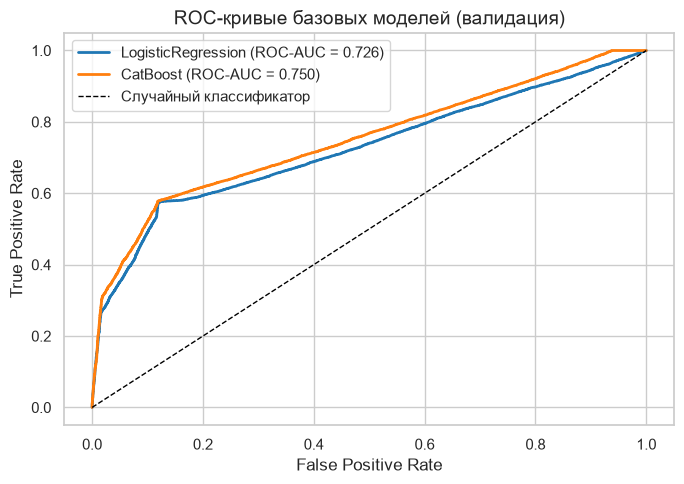

Точка отсчёта: LR = 0.7257, CatBoost = 0.7503. Лучшая базовая: cb_base.


In [ ]:
# Сводка базовых моделей + ROC-кривые
results = {'lr_base': lr_base_auc, 'cb_base': cb_base_auc}

fig, ax = plt.subplots(figsize=(7, 5))
for name, model, auc in [('LogisticRegression', lr_base, lr_base_auc),
                         ('CatBoost', cb_base, cb_base_auc)]:
    proba = model.predict_proba(df_val[BASE_FEATURES])[:, 1]
    fpr, tpr, _ = roc_curve(df_val[TARGET], proba)
    ax.plot(fpr, tpr, lw=2, label=f'{name} (ROC-AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Случайный классификатор')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC-кривые базовых моделей (валидация)')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Точка отсчёта: LR = {lr_base_auc:.4f}, CatBoost = {cb_base_auc:.4f}. Лучшая базовая: {max(results, key=results.get)}.')

## Кластеризация по признакам, связанным с местоположением

Превращаем координаты `customer_lat` / `customer_lon` в полезный признак -- логистическую зону.

- **Подготовка признаков.** K-Means минимизирует евклидовы расстояния, а градусы широты и долготы -- неодинаковые меры длины: 1° долготы ≈ 111·cos φ км, и на широтах наших клиентов (18–49°) разница достигает ~45%. Приводим координаты к плоским км (равнопромежуточная проекция с опорной широтой по train-выборке) и масштабируем StandardScaler для единого масштаба осей. Строго говоря, на этих данных кластеры и так разделились бы в градусах, но проекция делает расстояния физически корректными и не стоит ничего.
- **Защита от утечки.** Scaler и K-Means обучаем **только на клиентах обучающей выборки**, затем переносим разметку на клиентов val/test предсказанием ближайшего центроида (как работала бы система для нового клиента).
- **Число кластеров** подбираем методом локтя (максимальное удаление кривой инерции от хорды — математическая граница изгиба).
- **Карта кластеров** с центроидами.

Обучаем кластеризацию геозон на 12297 клиентах train-выборки


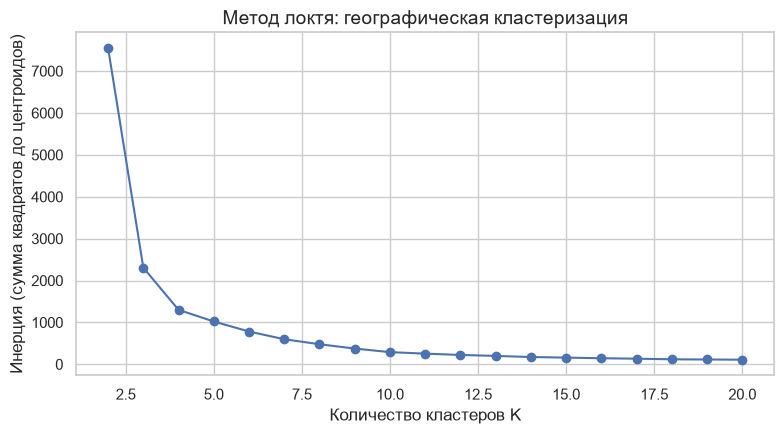

Изгиб кривой (макс. удаление от хорды) при K = 4


In [ ]:
# Приведение координат к плоским км и масштабирование (fit — только на train-клиентах, защита от утечки)
train_customer_ids = df_train['customer_id'].unique()
df_cust_train = df_customers[df_customers['customer_id'].isin(train_customer_ids)]

# Опорная широта проекции — тоже только по train-клиентам: константы пайплайна
# не должны опираться на val/test
LAT0_RAD = np.deg2rad(df_cust_train['customer_lat'].mean())

def coords_to_km(lat, lon):
    x = np.deg2rad(np.asarray(lon, dtype=float)) * 6371.0 * np.cos(LAT0_RAD)
    y = np.deg2rad(np.asarray(lat, dtype=float)) * 6371.0
    return np.column_stack([x, y])

X_geo_train_raw = coords_to_km(df_cust_train['customer_lat'], df_cust_train['customer_lon'])
X_geo_all_raw = coords_to_km(df_customers['customer_lat'], df_customers['customer_lon'])

geo_scaler = StandardScaler().fit(X_geo_train_raw)   # только обучающие клиенты
X_geo_train = geo_scaler.transform(X_geo_train_raw)
X_geo_all = geo_scaler.transform(X_geo_all_raw)

print(f'Обучаем кластеризацию геозон на {len(df_cust_train)} клиентах train-выборки')

# Метод локтя
GEO_K_RANGE = list(range(2, 21))
geo_inertias = []
for k in GEO_K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    km.fit(X_geo_train)
    geo_inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(GEO_K_RANGE, geo_inertias, 'o-', color='#4c72b0')
ax.set_xlabel('Количество кластеров K')
ax.set_ylabel('Инерция (сумма квадратов до центроидов)')
ax.set_title('Метод локтя: географическая кластеризация')
plt.tight_layout()
plt.show()


def find_elbow(ks, inertias):
    """K методом локтя: макс. расстояние кривой от хорды (нормализованные оси)."""
    x = np.asarray(ks, dtype=float)
    y = np.asarray(inertias, dtype=float)
    xn = (x - x[0]) / (x[-1] - x[0])
    yn = (y - y[-1]) / (y[0] - y[-1])
    dist = np.abs(xn + yn - 1) / np.sqrt(2)
    best = int(np.argmax(dist))
    return int(x[best]), dist


GEO_K, geo_elbow_dist = find_elbow(GEO_K_RANGE, geo_inertias)
print(f'Изгиб кривой (макс. удаление от хорды) при K = {GEO_K}')

In [ ]:
# Итоговая географическая кластеризация: fit на train-клиентах, разметка всех клиентов
geo_kmeans = KMeans(n_clusters=GEO_K, init='k-means++', n_init=10, random_state=RANDOM_STATE)
geo_kmeans.fit(X_geo_train)
df_customers['geo_cluster'] = geo_kmeans.predict(X_geo_all)

centroids_km = geo_scaler.inverse_transform(geo_kmeans.cluster_centers_)
cent_lat = np.rad2deg(centroids_km[:, 1] / 6371.0)
cent_lon = np.rad2deg(centroids_km[:, 0] / (6371.0 * np.cos(LAT0_RAD)))


def geo_zone_name(lat, lon):
    if lat < 22:
        return 'Пуэрто-Рико'
    if lon < -105:
        return 'Запад США'
    if lat >= 37:
        return 'Северо-Восток США'
    return 'Юг и Центр США'


zone_names = {i: geo_zone_name(cent_lat[i], cent_lon[i]) for i in range(GEO_K)}
print('Распределение клиентов по логистическим зонам:')
print(df_customers['geo_cluster'].value_counts().sort_index().to_string())

Распределение клиентов по логистическим зонам:
geo_cluster
0    7869
1    5572
2    2275
3    4780


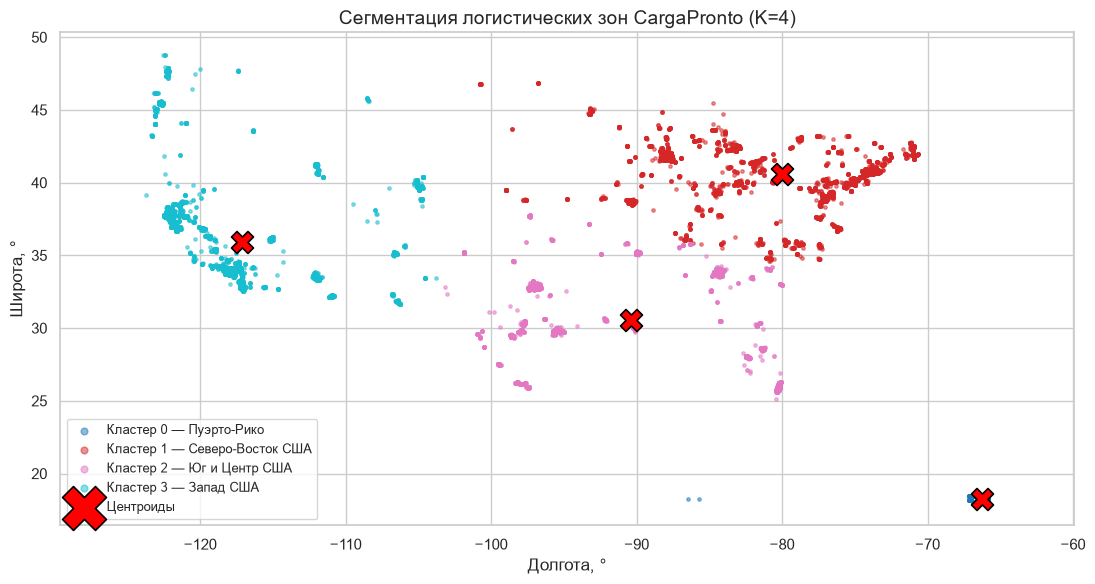

In [ ]:
# Карта логистических зон с центроидами
cmap_geo = plt.get_cmap('tab10' if GEO_K <= 10 else 'tab20', GEO_K)

fig, ax = plt.subplots(figsize=(11, 6))
for cl in sorted(df_customers['geo_cluster'].unique()):
    part = df_customers[df_customers['geo_cluster'] == cl]
    ax.scatter(part['customer_lon'], part['customer_lat'], s=6, alpha=0.5,
               color=cmap_geo(cl), label=f'Кластер {cl} — {zone_names[cl]}')
ax.scatter(cent_lon, cent_lat, marker='X', s=250, c='red', edgecolors='black',
           linewidths=1.2, zorder=5, label='Центроиды')
ax.set_xlabel('Долгота, °')
ax.set_ylabel('Широта, °')
ax.set_title(f'Сегментация логистических зон CargaPronto (K={GEO_K})')
ax.axis('equal')
ax.legend(markerscale=2, fontsize=9, loc='best')
plt.tight_layout()
plt.show()

In [ ]:
# Статистика геозон и их связь с задержками
geo_stats = (
    df_customers.groupby('geo_cluster')
    .agg(zone=('geo_cluster', lambda s: zone_names[s.iloc[0]]),
         customers=('customer_id', 'size'),
         lat_mean=('customer_lat', 'mean'),
         lon_mean=('customer_lon', 'mean'))
)
geo_stats['late_rate'] = (
    df_orders.merge(df_customers[['customer_id', 'geo_cluster']], on='customer_id')
    .groupby('geo_cluster')['late_delivery_risk'].mean()
)
display(geo_stats)
print('Логистические зоны компактны и интерпретируемы (Пуэрто-Рико / Запад / Северо-Восток / Юг).')
print('Средний уровень задержек по зонам почти одинаков, сама по себе география слабо разделяет риски.')

,zone,customers,lat_mean,lon_mean,late_rate
geo_cluster,,,,,
0,Пуэрто-Рико,7869,18.2515,-66.2325,0.5475
1,Северо-Восток США,5572,40.6006,-80.0294,0.5467
2,Юг и Центр США,2275,30.5309,-90.2826,0.5547
3,Запад США,4780,35.8838,-117.1333,0.5485


Логистические зоны компактны и интерпретируемы (Пуэрто-Рико / Запад / Северо-Восток / Юг).
Средний уровень задержек по зонам почти одинаков, сама по себе география слабо разделяет риски.


## Кластеризация по признакам профилей клиентов

Выделяем поведенческие сегменты по пятимерному вектору: `recency` (Recency), `total_orders` (Frequency), `total_sales` (Monetary), `return_rate` (добропорядочность), `avg_discount` (чувствительность к акциям).

- **Предобработка.** Признаки в разных единицах (дни, штуки, доллары, доли), без масштабирования K-Means проигнорирует малые масштабы. Применяем `StandardScaler` (fit — только на train-клиентах, защита от утечки).
- **Число кластеров** подбираем методом локтя.
- **Анализ кластеров** по средним значениям признаков; ярким сегментам присваиваем условные названия.
- **Визуализация** — t-SNE на масштабированных признаках (семплирование 8000 клиентов, `init='pca'`, `max_iter=500`, `perplexity=30`).
- **Ограничение данных.** RFM-признаки в CSV посчитаны ERP по всей истории клиента, включая заказы, совершённые позже прогнозируемого: GroupShuffleSplit защищает от «знакомства» с клиентом, но не от подглядывания в будущее. В продакшене такие агрегаты надо пересчитывать на момент оформления заказа; здесь работаем с выгрузкой «как есть» и учитываем это при интерпретации прироста качества (см. выводы).

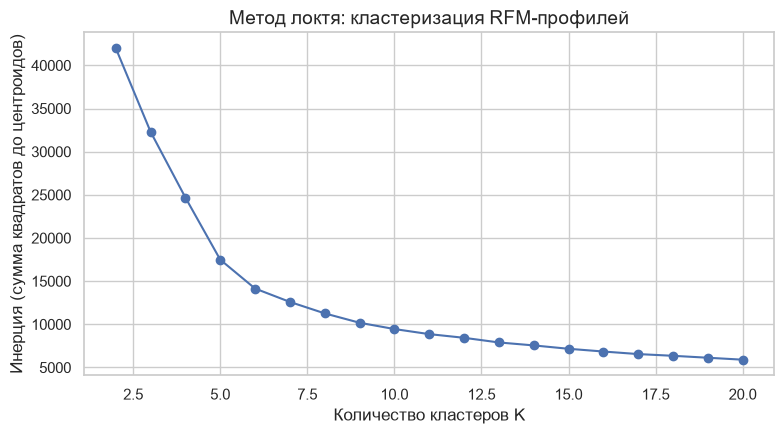

Изгиб кривой (макс. удаление от хорды) при K = 6


In [ ]:
RFM_FEATURES = ['recency', 'total_orders', 'total_sales', 'return_rate', 'avg_discount']

rfm_scaler = StandardScaler().fit(df_cust_train[RFM_FEATURES])   # только train-клиенты
X_rfm_train = rfm_scaler.transform(df_cust_train[RFM_FEATURES])
X_rfm_all = rfm_scaler.transform(df_customers[RFM_FEATURES])

# Метод локтя
RFM_K_RANGE = list(range(2, 21))
rfm_inertias = []
for k in RFM_K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    km.fit(X_rfm_train)
    rfm_inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(RFM_K_RANGE, rfm_inertias, 'o-', color='#4c72b0')
ax.set_xlabel('Количество кластеров K')
ax.set_ylabel('Инерция (сумма квадратов до центроидов)')
ax.set_title('Метод локтя: кластеризация RFM-профилей')
plt.tight_layout()
plt.show()

RFM_K, rfm_elbow_dist = find_elbow(RFM_K_RANGE, rfm_inertias)
print(f'Изгиб кривой (макс. удаление от хорды) при K = {RFM_K}')

In [ ]:
# Итоговая кластеризация профилей
rfm_kmeans = KMeans(n_clusters=RFM_K, init='k-means++', n_init=10, random_state=RANDOM_STATE)
rfm_kmeans.fit(X_rfm_train)
df_customers['beh_cluster'] = rfm_kmeans.predict(X_rfm_all)


def name_segment(row):
    """Условное название сегмента по его среднему профилю."""
    if row['return_rate'] > 0.5:
        return 'Проблемные возвратники'
    if row['recency'] > 500:
        return 'Спящие / ушедшие'
    if row['total_orders'] >= 5:
        return 'Лояльные VIP'
    if row['total_orders'] <= 1.5 and row['avg_discount'] >= 0.13:
        return 'Новички-скидочники'
    if row['total_orders'] <= 1.5:
        return 'Новички без скидок'
    return 'Стабильные середняки'


beh_stats = df_customers.groupby('beh_cluster')[RFM_FEATURES].mean()
beh_stats['customers'] = df_customers.groupby('beh_cluster')['customer_id'].size()
beh_stats['late_rate'] = (
    df_orders.merge(df_customers[['customer_id', 'beh_cluster']], on='customer_id')
    .groupby('beh_cluster')['late_delivery_risk'].mean()
)
beh_stats['segment'] = beh_stats.apply(name_segment, axis=1)
display(beh_stats.sort_values('customers', ascending=False))

print('Яркие сегменты:')
for cl, row in beh_stats.iterrows():
    print(f"  кластер {cl} «{row['segment']}»: recency={row['recency']:.0f}, orders={row['total_orders']:.1f}, "
          f"sales={row['total_sales']:.0f}, return_rate={row['return_rate']:.2f}, "
          f"avg_discount={row['avg_discount']:.2f}, late_rate={row['late_rate']:.2%}")

,recency,total_orders,total_sales,return_rate,avg_discount,customers,late_rate,segment
beh_cluster,,,,,,,,
3,263.6355,4.2769,2201.4836,0.0381,0.1023,6115,0.5488,Стабильные середняки
1,70.8590,1.0486,315.4923,0.0001,0.0481,4654,0.5744,Новички без скидок
2,72.1702,1.0558,277.1217,0.0003,0.1688,3761,0.5742,Новички-скидочники
5,240.4501,7.3189,4191.6435,0.0442,0.1009,3195,0.5497,Лояльные VIP
0,644.0289,2.7070,1390.4350,0.0240,0.1003,2287,0.5533,Спящие / ушедшие
4,157.5744,1.3554,506.6856,0.9249,0.1015,484,0.1361,Проблемные возвратники


Яркие сегменты:
  кластер 0 «Спящие / ушедшие»: recency=644, orders=2.7, sales=1390, return_rate=0.02, avg_discount=0.10, late_rate=55.33%
  кластер 1 «Новички без скидок»: recency=71, orders=1.0, sales=315, return_rate=0.00, avg_discount=0.05, late_rate=57.44%
  кластер 2 «Новички-скидочники»: recency=72, orders=1.1, sales=277, return_rate=0.00, avg_discount=0.17, late_rate=57.42%
  кластер 3 «Стабильные середняки»: recency=264, orders=4.3, sales=2201, return_rate=0.04, avg_discount=0.10, late_rate=54.88%
  кластер 4 «Проблемные возвратники»: recency=158, orders=1.4, sales=507, return_rate=0.92, avg_discount=0.10, late_rate=13.61%
  кластер 5 «Лояльные VIP»: recency=240, orders=7.3, sales=4192, return_rate=0.04, avg_discount=0.10, late_rate=54.97%


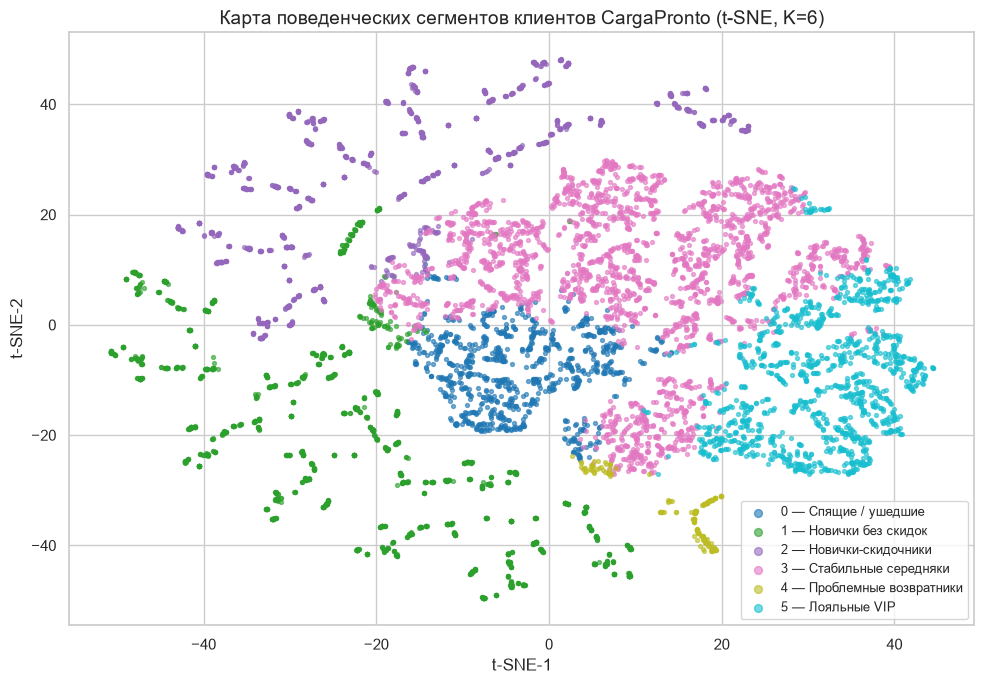

На проекции t-SNE сегменты выглядят компактными и разделимыми. Это визуальная проверка структуры, а не метрика качества: расстояния между группами на t-SNE-карте интерпретировать нельзя.


In [ ]:
# t-SNE: визуализация структуры сегментов (семплирование для скорости)
df_tsne = df_customers.sample(n=min(8000, len(df_customers)), random_state=RANDOM_STATE)
X_tsne = rfm_scaler.transform(df_tsne[RFM_FEATURES])

tsne = TSNE(n_components=2, perplexity=30, max_iter=500, init='pca',
            random_state=RANDOM_STATE, method='barnes_hut')
embedding = tsne.fit_transform(X_tsne)
df_tsne = df_tsne.copy()
df_tsne['tsne_1'] = embedding[:, 0]
df_tsne['tsne_2'] = embedding[:, 1]

fig, ax = plt.subplots(figsize=(10, 7))
cmap_beh = plt.get_cmap('tab10' if RFM_K <= 10 else 'tab20', RFM_K)
for cl in sorted(df_tsne['beh_cluster'].unique()):
    part = df_tsne[df_tsne['beh_cluster'] == cl]
    ax.scatter(part['tsne_1'], part['tsne_2'], s=8, alpha=0.6,
               color=cmap_beh(cl), label=f"{cl} — {beh_stats.loc[cl, 'segment']}")
ax.set_xlabel('t-SNE-1')
ax.set_ylabel('t-SNE-2')
ax.set_title(f'Карта поведенческих сегментов клиентов CargaPronto (t-SNE, K={RFM_K})')
ax.legend(markerscale=2, fontsize=9)
plt.tight_layout()
plt.show()
print('На проекции t-SNE сегменты выглядят компактными и разделимыми. Это визуальная проверка структуры, '
      'а не метрика качества: расстояния между группами на t-SNE-карте интерпретировать нельзя.')

## Обучение модели на новых признаках

- Добавляем результаты кластеризаций в данные: метки геокластеров — колонка `geo_cluster`, метки профилей — `beh_cluster` (слияние по `customer_id` во все три выборки).
- Убеждаемся, что после объединения нет пропусков и лишних дубликатов колонок.
- Обучаем финальные версии логистической регрессии (кластеры — категориальные, One-Hot) и CatBoostClassifier **с тем же набором гиперпараметров, что и базовая модель**, чтобы эффект новых признаков был «чистым».
- Считаем ROC-AUC на валидации и сравниваем с базовой точкой отсчёта.

**Идея эксперимента.** CatBoost обучаем в двух режимах: кластеры в `cat_features` (Ordered Target Statistics) и кластеры как числа (простые пороговые разбиения). Для большого K численная запись иногда работает устойчивее, потому что target statistics зашумляются на мелких кластерах.

In [ ]:
# Слияние меток кластеров в выборки по customer_id
cluster_map = df_customers.set_index('customer_id')[['geo_cluster', 'beh_cluster']]

df_train = df_train.join(cluster_map, on='customer_id')
df_val = df_val.join(cluster_map, on='customer_id')
df_test = df_test.join(cluster_map, on='customer_id')

for name, d in [('df_train', df_train), ('df_val', df_val), ('df_test', df_test)]:
    assert list(d.columns).count('geo_cluster') == 1 and list(d.columns).count('beh_cluster') == 1, 'Дубликаты колонок!'
    n_missing = int(d[['geo_cluster', 'beh_cluster']].isna().sum().sum())
    print(f'{name}: {d.shape[0]} строк, пропусков в кластерах: {n_missing}, '
          f'уникальных колонок: {d.columns.is_unique}')
    assert n_missing == 0

print('Объединение корректно: пропусков и дубликатов колонок нет.')

df_train: 107661 строк, пропусков в кластерах: 0, уникальных колонок: True
df_val: 35416 строк, пропусков в кластерах: 0, уникальных колонок: True
df_test: 36012 строк, пропусков в кластерах: 0, уникальных колонок: True
Объединение корректно: пропусков и дубликатов колонок нет.


In [ ]:
FULL_FEATURES = BASE_FEATURES + ['geo_cluster', 'beh_cluster']
CAT_FULL = CAT_COLS + ['geo_cluster', 'beh_cluster']


def as_cat(df):
    """Копия датафрейма с кластерами в строковом виде (режим категорий CatBoost)."""
    out = df.copy()
    out['geo_cluster'] = out['geo_cluster'].astype(str)
    out['beh_cluster'] = out['beh_cluster'].astype(str)
    return out


# Логистическая регрессия: кластеры закодируем как категориальные признаки
preprocessor_lr_full = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FULL),
    ('num', StandardScaler(), NUM_COLS),
])
lr_full = Pipeline([
    ('pre', preprocessor_lr_full),
    ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
lr_full.fit(df_train[FULL_FEATURES], df_train[TARGET])
lr_full_auc = roc_auc_score(df_val[TARGET], lr_full.predict_proba(df_val[FULL_FEATURES])[:, 1])
print(f'LogisticRegression (+ кластеры) — val ROC-AUC = {lr_full_auc:.4f} (базовая {lr_base_auc:.4f}, Δ {lr_full_auc - lr_base_auc:+.4f})')

LogisticRegression (+ кластеры) — val ROC-AUC = 0.7291 (базовая 0.7257, Δ +0.0034)


In [ ]:
# CatBoost: два режима работы с кластерами, гиперпараметры как у базовой модели
cb_full_num = CatBoostClassifier(**CB_PARAMS, cat_features=CAT_COLS)
cb_full_num.fit(df_train[FULL_FEATURES], df_train[TARGET])
cb_full_num_auc = roc_auc_score(df_val[TARGET], cb_full_num.predict_proba(df_val[FULL_FEATURES])[:, 1])

cb_full_cat = CatBoostClassifier(**CB_PARAMS, cat_features=CAT_FULL)
cb_full_cat.fit(as_cat(df_train)[FULL_FEATURES], df_train[TARGET])
cb_full_cat_auc = roc_auc_score(
    df_val[TARGET], cb_full_cat.predict_proba(as_cat(df_val)[FULL_FEATURES])[:, 1]
)

print(f'CatBoost, кластеры как числа      — val ROC-AUC = {cb_full_num_auc:.4f} (Δ {cb_full_num_auc - cb_base_auc:+.4f})')
print(f'CatBoost, кластеры как категории  — val ROC-AUC = {cb_full_cat_auc:.4f} (Δ {cb_full_cat_auc - cb_base_auc:+.4f})')

print('Итоговый режим кодирования кластеров выбирается ниже, вместе с конфигурацией K по перебору.')

CatBoost, кластеры как числа      — val ROC-AUC = 0.7547 (Δ +0.0044)
CatBoost, кластеры как категории  — val ROC-AUC = 0.7554 (Δ +0.0051)
Итоговый режим кодирования кластеров выбирается ниже, вместе с конфигурацией K по перебору.


In [ ]:
# Сравнение всех подходов на валидации
comparison = pd.DataFrame({
    'модель': [
        'LogisticRegression (базовая)',
        'CatBoost (базовая)',
        'LogisticRegression (+ кластеры)',
        'CatBoost (+ кластеры, числа)',
        'CatBoost (+ кластеры, категории)',
    ],
    'val ROC-AUC': [lr_base_auc, cb_base_auc, lr_full_auc, cb_full_num_auc, cb_full_cat_auc],
})
comparison['Δ к лучшей базовой'] = comparison['val ROC-AUC'] - max(lr_base_auc, cb_base_auc)
comparison = comparison.sort_values('val ROC-AUC', ascending=False)
display(comparison.style.format({'val ROC-AUC': '{:.4f}', 'Δ к лучшей базовой': '{:+.4f}'}))

best_with_clusters = comparison['val ROC-AUC'].max()
print(f'Лучший результат с кластерами: {best_with_clusters:.4f} против {max(lr_base_auc, cb_base_auc):.4f} у базовой — '
      f'прирост {best_with_clusters - max(lr_base_auc, cb_base_auc):+.4f} ROC-AUC.')

,модель,val ROC-AUC,Δ к лучшей базовой
4,"CatBoost (+ кластеры, категории)",0.7554,+0.0051
3,"CatBoost (+ кластеры, числа)",0.7547,+0.0044
1,CatBoost (базовая),0.7503,+0.0000
2,LogisticRegression (+ кластеры),0.7291,-0.0213
0,LogisticRegression (базовая),0.7257,-0.0246


Лучший результат с кластерами: 0.7554 против 0.7503 у базовой — прирост +0.0051 ROC-AUC.


## Дополнительное задание (подбор оптимального количества кластеров)

Метод локтя даёт математически обоснованный минимум, но степень детализации сегментов можно рассматривать как гиперпараметр всей системы. Перебираем `geo_k_range = [4, 8, 12, 20]` и `rfm_k_range = [6, 12, 20, 30]`, для каждой пары обучаем CatBoost и выбираем K с максимальным ROC-AUC на валидации. Кластеризацию внутри перебора обучаем только на train-клиентах (без утечки); для скорости перебора используем уменьшенное `iterations=500`, финальная модель будет дообучена с базовыми гиперпараметрами.

In [ ]:
geo_k_range = [4, 8, 12, 20]
rfm_k_range = [6, 12, 20, 30]
GRID_CB_PARAMS = dict(CB_PARAMS, iterations=500)


def build_cluster_features(geo_k, rfm_k):
    """Обучает KMeans на train-клиентах и добавляет метки во все выборки."""
    gkm = KMeans(n_clusters=geo_k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    gkm.fit(X_geo_train)
    rkm = KMeans(n_clusters=rfm_k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    rkm.fit(X_rfm_train)

    cmap = pd.DataFrame({
        'customer_id': df_customers['customer_id'].values,
        'geo_cluster': gkm.predict(X_geo_all),
        'beh_cluster': rkm.predict(X_rfm_all),
    }).set_index('customer_id')

    out = {}
    for split_name, base_df in [('train', df_train), ('val', df_val), ('test', df_test)]:
        d = base_df.drop(columns=['geo_cluster', 'beh_cluster']).join(cmap, on='customer_id')
        assert d[['geo_cluster', 'beh_cluster']].isna().sum().sum() == 0
        out[split_name] = d
    return out, gkm, rkm


grid_rows = []
for gk in geo_k_range:
    for rk in rfm_k_range:
        feats, _, _ = build_cluster_features(gk, rk)
        # режим: кластеры как числа
        model_num = CatBoostClassifier(**GRID_CB_PARAMS, cat_features=CAT_COLS)
        model_num.fit(feats['train'][FULL_FEATURES], feats['train'][TARGET])
        auc_num = roc_auc_score(feats['val'][TARGET], model_num.predict_proba(feats['val'][FULL_FEATURES])[:, 1])
        # режим: кластеры как категории
        model_cat = CatBoostClassifier(**GRID_CB_PARAMS, cat_features=CAT_FULL)
        model_cat.fit(as_cat(feats['train'])[FULL_FEATURES], feats['train'][TARGET])
        auc_cat = roc_auc_score(
            feats['val'][TARGET],
            model_cat.predict_proba(as_cat(feats['val'])[FULL_FEATURES])[:, 1]
        )
        grid_rows.append({'geo_k': gk, 'rfm_k': rk, 'auc_num': auc_num, 'auc_cat': auc_cat})
        print(f'geo_k={gk:>2} rfm_k={rk:>2} | числа={auc_num:.4f} категории={auc_cat:.4f}', flush=True)

grid_results = pd.DataFrame(grid_rows)
grid_results['best_auc'] = grid_results[['auc_num', 'auc_cat']].max(axis=1)
display(grid_results.sort_values('best_auc', ascending=False))

geo_k= 4 rfm_k= 6 | числа=0.7548 категории=0.7530
geo_k= 4 rfm_k=12 | числа=0.7663 категории=0.7645
geo_k= 4 rfm_k=20 | числа=0.7648 категории=0.7658
geo_k= 4 rfm_k=30 | числа=0.7639 категории=0.7658
geo_k= 8 rfm_k= 6 | числа=0.7552 категории=0.7550
geo_k= 8 rfm_k=12 | числа=0.7657 категории=0.7641
geo_k= 8 rfm_k=20 | числа=0.7659 категории=0.7663
geo_k= 8 rfm_k=30 | числа=0.7639 категории=0.7628
geo_k=12 rfm_k= 6 | числа=0.7532 категории=0.7539
geo_k=12 rfm_k=12 | числа=0.7667 категории=0.7634
geo_k=12 rfm_k=20 | числа=0.7635 категории=0.7629
geo_k=12 rfm_k=30 | числа=0.7640 категории=0.7614
geo_k=20 rfm_k= 6 | числа=0.7567 категории=0.7557
geo_k=20 rfm_k=12 | числа=0.7680 категории=0.7630
geo_k=20 rfm_k=20 | числа=0.7645 категории=0.7644
geo_k=20 rfm_k=30 | числа=0.7641 категории=0.7591


,geo_k,rfm_k,auc_num,auc_cat,best_auc
13,20,12,0.7680,0.7630,0.7680
9,12,12,0.7667,0.7634,0.7667
1,4,12,0.7663,0.7645,0.7663
6,8,20,0.7659,0.7663,0.7663
2,4,20,0.7648,0.7658,0.7658
3,4,30,0.7639,0.7658,0.7658
5,8,12,0.7657,0.7641,0.7657
14,20,20,0.7645,0.7644,0.7645
15,20,30,0.7641,0.7591,0.7641
11,12,30,0.7640,0.7614,0.7640


geo_k= 4 rfm_k=20 | числа=0.7648 категории=0.7658


geo_k= 4 rfm_k=30 | числа=0.7639 категории=0.7658


geo_k= 8 rfm_k= 6 | числа=0.7552 категории=0.7550


...

geo_k=20 rfm_k= 6 | числа=0.7567 категории=0.7557


geo_k=20 rfm_k=12 | числа=0.7680 категории=0.7630


geo_k=20 rfm_k=20 | числа=0.7645 категории=0.7644


geo_k=20 rfm_k=30 | числа=0.7641 категории=0.7591


,geo_k,rfm_k,auc_num,auc_cat,best_auc
13,20,12,0.7680,0.7630,0.7680
9,12,12,0.7667,0.7634,0.7667
1,4,12,0.7663,0.7645,0.7663
6,8,20,0.7659,0.7663,0.7663
2,4,20,0.7648,0.7658,0.7658
3,4,30,0.7639,0.7658,0.7658
5,8,12,0.7657,0.7641,0.7657
14,20,20,0.7645,0.7644,0.7645
15,20,30,0.7641,0.7591,0.7641
11,12,30,0.7640,0.7614,0.7640


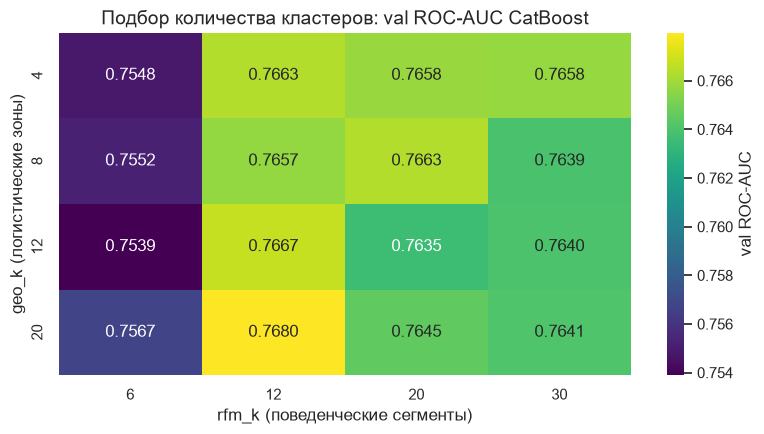

Лучшая конфигурация: geo_k=20, rfm_k=12, режим кластеров=num, val ROC-AUC = 0.7680


In [ ]:
# Тепловая карта качества перебора (лучший из двух режимов кластеров)
pivot = grid_results.pivot(index='geo_k', columns='rfm_k', values='best_auc')
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='viridis', ax=ax, cbar_kws={'label': 'val ROC-AUC'})
ax.set_title('Подбор количества кластеров: val ROC-AUC CatBoost')
ax.set_xlabel('rfm_k (поведенческие сегменты)')
ax.set_ylabel('geo_k (логистические зоны)')
plt.tight_layout()
plt.show()

best_row = grid_results.loc[grid_results['best_auc'].idxmax()]
BEST_GEO_K = int(best_row['geo_k'])
BEST_RFM_K = int(best_row['rfm_k'])
BEST_ENCODING = 'num' if best_row['auc_num'] >= best_row['auc_cat'] else 'cat'
print(f'Лучшая конфигурация: geo_k={BEST_GEO_K}, rfm_k={BEST_RFM_K}, режим кластеров={BEST_ENCODING}, '
      f'val ROC-AUC = {best_row["best_auc"]:.4f}')

## Тестирование лучшей модели

Проверяем, что выбранная модель сохраняет качество на данных, которые она никогда не видела, и понимаем, какие факторы стали решающими.

- Перестраиваем признаки на лучшей паре (geo_k, rfm_k) и обучаем финальные модели с **базовыми гиперпараметрами** CatBoost; лучшую выбираем по валидации и оцениваем на тесте (цель — ROC-AUC > 0.75).
- Строим матрицу ошибок (порог 0.50 и бизнес-порог 0.70 из постановки задачи) и определяем преобладающий тип ошибок.
- Визуализируем важность признаков и анализируем позиции `geo_cluster` и `beh_cluster` в рейтинге.

In [ ]:
# Признаки лучшей конфигурации + финальные модели с базовыми гиперпараметрами
feats_best, geo_kmeans_final, rfm_kmeans_final = build_cluster_features(BEST_GEO_K, BEST_RFM_K)
feats_best_cat = {k: as_cat(v) for k, v in feats_best.items()}

final_candidates = {}

lr_final = Pipeline([
    ('pre', clone(preprocessor_lr_full)),
    ('clf', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
lr_final.fit(feats_best['train'][FULL_FEATURES], feats_best['train'][TARGET])
final_candidates['LogisticRegression'] = {
    'model': lr_final,
    'val_auc': roc_auc_score(feats_best['val'][TARGET], lr_final.predict_proba(feats_best['val'][FULL_FEATURES])[:, 1]),
    'cat_mode': False,
}

cb_final_num = CatBoostClassifier(**CB_PARAMS, cat_features=CAT_COLS)
cb_final_num.fit(feats_best['train'][FULL_FEATURES], feats_best['train'][TARGET])
final_candidates['CatBoost (числа)'] = {
    'model': cb_final_num,
    'val_auc': roc_auc_score(feats_best['val'][TARGET], cb_final_num.predict_proba(feats_best['val'][FULL_FEATURES])[:, 1]),
    'cat_mode': False,
}

cb_final_cat = CatBoostClassifier(**CB_PARAMS, cat_features=CAT_FULL)
cb_final_cat.fit(feats_best_cat['train'][FULL_FEATURES], feats_best['train'][TARGET])
final_candidates['CatBoost (категории)'] = {
    'model': cb_final_cat,
    'val_auc': roc_auc_score(feats_best['val'][TARGET], cb_final_cat.predict_proba(feats_best_cat['val'][FULL_FEATURES])[:, 1]),
    'cat_mode': True,
}

final_table = pd.DataFrame(
    [{'модель': name, 'val ROC-AUC': info['val_auc']} for name, info in final_candidates.items()]
).sort_values('val ROC-AUC', ascending=False)
display(final_table.style.format({'val ROC-AUC': '{:.4f}'}))

best_name = final_table.iloc[0]['модель']
final_model = final_candidates[best_name]['model']
final_cat_mode = final_candidates[best_name]['cat_mode']
final_val_auc = final_candidates[best_name]['val_auc']
print(f'Лучшая модель: {best_name}, val ROC-AUC = {final_val_auc:.4f}')

,модель,val ROC-AUC
1,CatBoost (числа),0.7669
2,CatBoost (категории),0.7635
0,LogisticRegression,0.7426


Лучшая модель: CatBoost (числа), val ROC-AUC = 0.7669


ИТОГОВЫЙ ROC-AUC на тесте: 0.7721 (цель > 0.75 — ДОСТИГНУТА)
Базовые модели на том же тесте: LR = 0.7290, CatBoost = 0.7570 → вклад кластеров на тесте +0.0151
val 0.7669 / test 0.7721, разрыв +0.0052 — разрыв невелик, признаков переобучения не видно


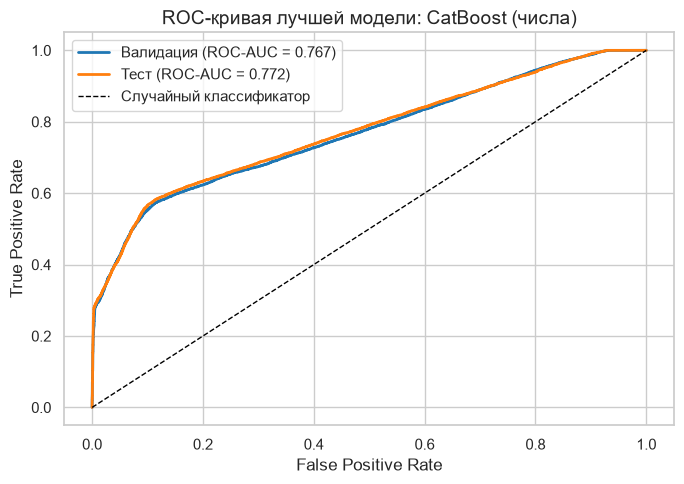

In [ ]:
# Предсказание на тестовой выборке + сравнение с базовыми моделями на том же тесте
X_test = feats_best_cat['test'][FULL_FEATURES] if final_cat_mode else feats_best['test'][FULL_FEATURES]
X_val = feats_best_cat['val'][FULL_FEATURES] if final_cat_mode else feats_best['val'][FULL_FEATURES]
y_test = feats_best['test'][TARGET]
y_val = feats_best['val'][TARGET]

val_proba = final_model.predict_proba(X_val)[:, 1]
test_proba = final_model.predict_proba(X_test)[:, 1]
final_test_auc = roc_auc_score(y_test, test_proba)

# Базовые модели на том же тесте: дельта «кластеры против базы» обязана считаться на одной выборке
lr_base_test_auc = roc_auc_score(df_test[TARGET], lr_base.predict_proba(df_test[BASE_FEATURES])[:, 1])
cb_base_test_auc = roc_auc_score(df_test[TARGET], cb_base.predict_proba(df_test[BASE_FEATURES])[:, 1])
best_base_test_auc = max(lr_base_test_auc, cb_base_test_auc)
gap = final_test_auc - final_val_auc

print(f'ИТОГОВЫЙ ROC-AUC на тесте: {final_test_auc:.4f} (цель > 0.75 — {"ДОСТИГНУТА" if final_test_auc > 0.75 else "НЕ достигнута"})')
print(f'Базовые модели на том же тесте: LR = {lr_base_test_auc:.4f}, CatBoost = {cb_base_test_auc:.4f} '
      f'→ вклад кластеров на тесте {final_test_auc - best_base_test_auc:+.4f}')
print(f'val {final_val_auc:.4f} / test {final_test_auc:.4f}, разрыв {gap:+.4f} — '
      + ('разрыв невелик, признаков переобучения не видно' if abs(gap) < 0.01
         else 'валидация оказалась оптимистичнее теста'))

fig, ax = plt.subplots(figsize=(7, 5))
fpr_v, tpr_v, _ = roc_curve(y_val, val_proba)
fpr_t, tpr_t, _ = roc_curve(y_test, test_proba)
ax.plot(fpr_v, tpr_v, lw=2, label=f'Валидация (ROC-AUC = {final_val_auc:.3f})')
ax.plot(fpr_t, tpr_t, lw=2, label=f'Тест (ROC-AUC = {final_test_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Случайный классификатор')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title(f'ROC-кривая лучшей модели: {best_name}')
ax.legend()
plt.tight_layout()
plt.show()

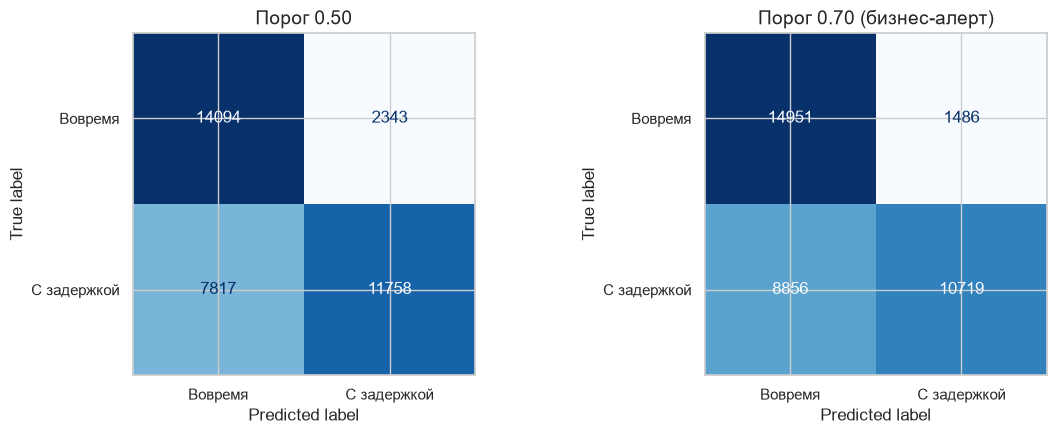

Порог 0.50: TN=14094, FP=2343, FN=7817, TP=11758 | пропуски задержек (FN)=39.9%, ложные тревоги (FP)=14.3%, precision=83.4%, recall=60.1%
Порог 0.70: TN=14951, FP=1486, FN=8856, TP=10719 | пропуски задержек (FN)=45.2%, ложные тревоги (FP)=9.0%, precision=87.8%, recall=54.8%

Модель чаще пропускает реальные задержки (FN=7817 против FP=2343 при пороге 0.50, recall 60%).
Повышение порога эту проблему не решает: на пороге 0.70 пропусков ещё больше (см. матрицы выше) —
высокий порог отсекает «слабые» тревоги вместе с частью истинных опозданий.
Операционная схема: рабочую границу держать около 0.50 и ниже (максимум охвата опозданий),
а 0.70 использовать как уровень срочных мер, где ложные тревоги редки (precision ~88%).


In [ ]:
# Матрицы ошибок: операционный порог 0.50 и бизнес-порог 0.70 (предупреждение «риск > 70%»)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, thr, title in [(axes[0], 0.50, 'Порог 0.50'), (axes[1], 0.70, 'Порог 0.70 (бизнес-алерт)')]:
    pred = (test_proba >= thr).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=['Вовремя', 'С задержкой']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

for thr in (0.50, 0.70):
    pred = (test_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f'Порог {thr:.2f}: TN={tn}, FP={fp}, FN={fn}, TP={tp} | '
          f'пропуски задержек (FN)={fn / (fn + tp):.1%}, ложные тревоги (FP)={fp / (fp + tn):.1%}, '
          f'precision={tp / (tp + fp):.1%}, recall={tp / (tp + fn):.1%}')

tn, fp, fn, tp = confusion_matrix(y_test, (test_proba >= 0.5).astype(int)).ravel()
print()
if fn > fp:
    print(f'Модель чаще пропускает реальные задержки (FN={fn} против FP={fp} при пороге 0.50, recall {tp / (tp + fn):.0%}).')
    print('Повышение порога эту проблему не решает: на пороге 0.70 пропусков ещё больше (см. матрицы выше) —')
    print('высокий порог отсекает «слабые» тревоги вместе с частью истинных опозданий.')
    print('Операционная схема: рабочую границу держать около 0.50 и ниже (максимум охвата опозданий),')
    print('а 0.70 использовать как уровень срочных мер, где ложные тревоги редки (precision ~88%).')
else:
    print(f'Модель чаще выдаёт ложные тревоги (FP={fp} > FN={fn}): часть предупреждений не подтвердится, '
          'но предупреждённая задержка дешевле внезапного опоздания (постановка задачи).')

In [ ]:
# Демонстрация системы поддержки решений на примере тестовых заказов
demo = feats_best['test'][['order_id', 'customer_id'] + FULL_FEATURES].copy()
demo['risk_proba'] = test_proba
demo = demo.sort_values('risk_proba', ascending=False).head(5)
print('Пример работы системы предупреждений (топ-5 самых рискованных заказов теста):')
for _, r in demo.iterrows():
    alert = ('Внимание! Данный заказ имеет высокий риск задержки '
             f'({r["risk_proba"]:.0%}). Рекомендуется сменить приоритет доставки.') if r['risk_proba'] > 0.70 else ''
    print(f"  order_id={int(r['order_id'])}, клиент={int(r['customer_id'])}, "
          f"geo_cluster={int(r['geo_cluster'])}, beh_cluster={int(r['beh_cluster'])}, "
          f"риск={r['risk_proba']:.0%} {alert}")

Пример работы системы предупреждений (топ-5 самых рискованных заказов теста):
  order_id=175932, клиент=16170, geo_cluster=14, beh_cluster=0, риск=100% Внимание! Данный заказ имеет высокий риск задержки (100%). Рекомендуется сменить приоритет доставки.
  order_id=3765, клиент=6622, geo_cluster=8, beh_cluster=1, риск=100% Внимание! Данный заказ имеет высокий риск задержки (100%). Рекомендуется сменить приоритет доставки.
  order_id=120789, клиент=6610, geo_cluster=18, beh_cluster=1, риск=100% Внимание! Данный заказ имеет высокий риск задержки (100%). Рекомендуется сменить приоритет доставки.
  order_id=120790, клиент=6610, geo_cluster=18, beh_cluster=1, риск=100% Внимание! Данный заказ имеет высокий риск задержки (100%). Рекомендуется сменить приоритет доставки.
  order_id=3756, клиент=8566, geo_cluster=11, beh_cluster=1, риск=100% Внимание! Данный заказ имеет высокий риск задержки (100%). Рекомендуется сменить приоритет доставки.


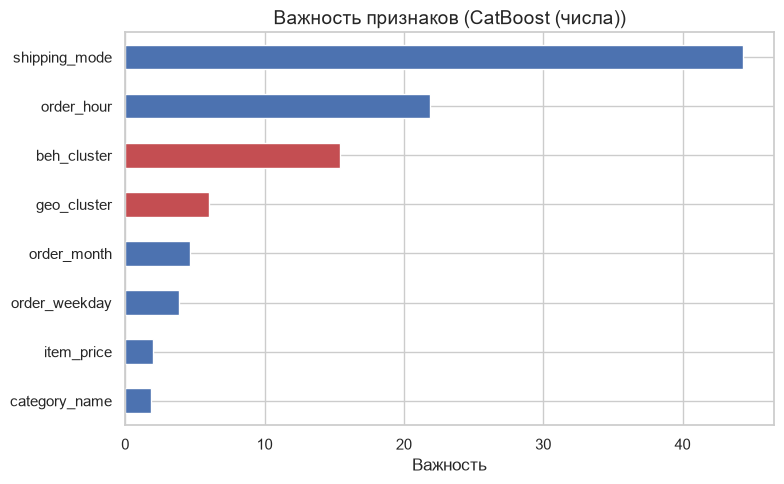

,feature,importance,rank
0,shipping_mode,44.3481,1
1,order_hour,21.8870,2
2,beh_cluster,15.3845,3
3,geo_cluster,5.9960,4
4,order_month,4.6313,5
5,order_weekday,3.8774,6
6,item_price,2.0103,7
7,category_name,1.8654,8


Позиции созданных признаков в рейтинге:
  geo_cluster: место 4 из 8, важность = 6.00
  beh_cluster: место 3 из 8, важность = 15.38


In [ ]:
# Важность признаков лучшей модели
if best_name.startswith('CatBoost'):
    importances = pd.Series(final_model.get_feature_importance(), index=final_model.feature_names_)
else:
    ohe_names = (final_model.named_steps['pre']
                 .named_transformers_['cat']
                 .get_feature_names_out(CAT_FULL).tolist())
    coefs = final_model.named_steps['clf'].coef_[0]
    importances = pd.Series(np.abs(coefs), index=ohe_names + NUM_COLS)

importances = importances.sort_values(ascending=False)
cluster_features = ['geo_cluster', 'beh_cluster']

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#c44e52' if any(cf in name for cf in cluster_features) else '#4c72b0' for name in importances.index]
importances.plot(kind='barh', ax=ax, color=colors)
ax.set_title(f'Важность признаков ({best_name})')
ax.set_xlabel('Важность')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

ranking = importances.reset_index()
ranking.columns = ['feature', 'importance']
ranking['rank'] = ranking.index + 1
display(ranking)

print('Позиции созданных признаков в рейтинге:')
for cf in cluster_features:
    rows_cf = ranking[ranking['feature'].str.startswith(cf)]
    for _, r in rows_cf.iterrows():
        print(f"  {r['feature']}: место {int(r['rank'])} из {len(ranking)}, важность = {r['importance']:.2f}")

In [ ]:
# СВОДКА ДЛЯ ВЫВОДОВ
print('===== СВОДКА =====')
print(f'lr_base_auc={lr_base_auc:.4f}')
print(f'cb_base_auc={cb_base_auc:.4f}')
print(f'lr_base_test_auc={lr_base_test_auc:.4f}')
print(f'cb_base_test_auc={cb_base_test_auc:.4f}')
print(f'lr_full_auc={lr_full_auc:.4f}')
print(f'cb_full_num_auc={cb_full_num_auc:.4f}')
print(f'cb_full_cat_auc={cb_full_cat_auc:.4f}')
print(f'elbow_geo_k={GEO_K} elbow_rfm_k={RFM_K}')
print(f'best_grid_geo_k={BEST_GEO_K} best_grid_rfm_k={BEST_RFM_K} best_grid_encoding={BEST_ENCODING} best_grid_auc={best_row["best_auc"]:.4f}')
print(f'final_model={best_name} final_val_auc={final_val_auc:.4f} final_test_auc={final_test_auc:.4f}')
tn, fp, fn, tp = confusion_matrix(y_test, (test_proba >= 0.5).astype(int)).ravel()
print(f'cm_050=tn{tn}_fp{fp}_fn{fn}_tp{tp}')
tn7, fp7, fn7, tp7 = confusion_matrix(y_test, (test_proba >= 0.7).astype(int)).ravel()
print(f'cm_070=tn{tn7}_fp{fp7}_fn{fn7}_tp{tp7}')
print('top_features=' + ', '.join(f'{n}:{v:.1f}' for n, v in importances.head(6).items()))
print('geo_late_rates=' + ', '.join(f'{k}:{v:.3f}' for k, v in geo_stats['late_rate'].items()))
print('segments=' + ' | '.join(f"{int(i)}:{row['segment']}(late={row['late_rate']:.2%})"
                               for i, row in beh_stats.sort_index().iterrows()))

===== СВОДКА =====
lr_base_auc=0.7257
cb_base_auc=0.7503
lr_base_test_auc=0.7290
cb_base_test_auc=0.7570
lr_full_auc=0.7291
cb_full_num_auc=0.7547
cb_full_cat_auc=0.7554
elbow_geo_k=4 elbow_rfm_k=6
best_grid_geo_k=20 best_grid_rfm_k=12 best_grid_encoding=num best_grid_auc=0.7680
final_model=CatBoost (числа) final_val_auc=0.7669 final_test_auc=0.7721
cm_050=tn14094_fp2343_fn7817_tp11758
cm_070=tn14951_fp1486_fn8856_tp10719
top_features=shipping_mode:44.3, order_hour:21.9, beh_cluster:15.4, geo_cluster:6.0, order_month:4.6, order_weekday:3.9
geo_late_rates=0:0.548, 1:0.547, 2:0.555, 3:0.548
segments=0:Спящие / ушедшие(late=55.33%) | 1:Новички без скидок(late=57.44%) | 2:Новички-скидочники(late=57.42%) | 3:Стабильные середняки(late=54.88%) | 4:Проблемные возвратники(late=13.61%) | 5:Лояльные VIP(late=54.97%)


## Выводы и рекомендации

### 1. Результаты моделирования
- Базовые модели (только признаки заказа): валидация LR 0.7257, CatBoost 0.7503; тест — LR 0.7290, CatBoost 0.7570. Базовый бустинг проходит целевую планку 0.75 уже без кластеров.
- Кластеры по методу локтя (geo_k=4, rfm_k=6), валидация: LR 0.7291 (+0.003), CatBoost 0.7547–0.7554 (+0.004…+0.005). Прибавка скромная: грубые корзины сжимают сигнал профиля клиента.
- Перебор детализации (geo_k × rfm_k из {4, 8, 12, 20} × {6, 12, 20, 30}): лучшая пара geo_k=20, rfm_k=12, кластеры числами — val 0.7680, +0.018 к лучшей базовой на валидации. Соседние конфигурации отличаются на 0.002–0.004, значимость разниц не проверяли, поэтому K корректнее считать слабым гиперпараметром.
- Финальная модель CatBoost (кластеры числами, 20×12): val 0.7669, тест 0.7721. Цель > 0.75 достигнута. Вклад кластеров против базового CatBoost на том же тесте +0.0151 (0.7721 против 0.7570); разрыв val↔test +0.005, заметного переобучения нет.
- Матрица ошибок на тесте. Порог 0.50: TN=14094, FP=2343, FN=7817, TP=11758 — recall 60.1%, precision 83.4%. Порог 0.70: TN=14951, FP=1486, FN=8856, TP=10719 — recall 54.8%, precision 87.8%. Дисбаланс смещён в сторону пропусков, и повышение порога пропуски не сокращает, а увеличивает.

### 2. Эффективность сегментации
- Гипотеза о «проблемных клиентах» подтверждается наполовину: поведенческий профиль в прогнозе работает, география -- практически нет.
- Доли задержек по зонам: 54.7–55.5% (Пуэрто-Рико 54.8%, Юг и Центр 55.5%, Северо-Восток 54.7%, Запад 54.8%). geo_cluster занимает 4-е место по важности (6.0%) — местоположение работает как контекст, самостоятельного драйвера риска в нём нет.
- beh_cluster — 3-е место (15.4%) после shipping_mode (44.3%) и order_hour (21.9%). Наиболее контрастный сегмент — «Проблемные возвратники» (return_rate ≈ 0.92, 484 клиента): 13.6% задержек против ~55% в среднем. Остальные сегменты близки (54.9–57.4%): поведенческие кластеры информативнее географических (15.4% против 6.0% важности), но основной разброс рисков они не объясняют.
- Ограничение: RFM-признаки выгружены ERP по всей истории клиента, включая заказы после прогнозируемого момента. GroupShuffleSplit исключает «знакомство» с клиентом, но не утечку из будущего, поэтому часть вклада beh_cluster может быть завышена. Для продакшена агрегаты нужно пересчитывать на момент оформления заказа.
- Итог по гипотезе: риск задают параметры самого заказа. В первую очередь режим доставки (First Class опаздывает в 95% заказов, Second Class в 77%, Standard Class в 38%) и час оформления. Знание сегментов улучшает прогноз, но не заменяет работу с режимами доставки.

### 3. Технический инсайт
- Метод локтя дал K_geo=4 и K_rfm=6. Эти значения хорошо интерпретируются (зоны совпали с Пуэрто-Рико / Запад / Северо-Восток / Юг), но для прогноза полезнее детализация 20×12.
- Очевидное объяснение «большой K вредит из-за зашумлённых target statistics» данными не подтверждается: в числовом режиме, где target statistics не участвуют, качество при rfm_k=30 падает так же (0.7680 → 0.7641). Просадку при крупном K корректнее объяснять ростом дисперсии на мелких группах, а не спецификой CatBoost.
- Формат кластеров: на грубой сетке (4×6) режимы почти равны (числа 0.7548 против категорий 0.7530), на детальной (20×12) числовая запись впереди (0.7680 против 0.7630). Тренд совпадает с предположением методички из задания к проекту, но разница в пределах шума, поэтому стратегический вывод из неё делать рано.
- Объективаность оценки: валидация использовалась и для выбора кодирования кластеров, и для перебора K, поэтому val-числа смещены вверх; несмещённая оценка качества — тестовые 0.7721. Scaler и оба K-Means обучены только на train-клиентах (включая опорную широту проекции), val/test размечены предсказанием ближайшего центроида, пересечений клиентов между выборками нет.

### 4. Бизнес-рекомендации
1. Скоринг в момент оформления заказа (артефакты: `cargapronto_delay_pipeline.joblib`, `cargapronto_delay_model.cbm`): при p > 0.70 — алерт и внеочередная сборка. Оценить объём: на тесте такой алерт сработал бы на ~34% заказов (12 205 из 36 012), при пороге 0.50 на ~39%. Если мощности диспетчерской не хватает, работать топ-N заказов по убыванию риска, а не по фиксированному порогу.
2. Рабочий порог держать около 0.50 (recall 60%, precision 83%): модель чаще пропускает реальные задержки, и повышение порога это усугубляет. Порог 0.70 — уровень срочных мер, где ложные тревоги редки (precision 88%).
3. Разобраться с режимами доставки (главным фактором риска): First Class срывается в 95% случаев, Second Class в 77% при 38% у Standard Class. Пересмотреть нормативы для скоростных режимов; там, где они систематически не успевают, ограничить продажу или заранее закладывать апгрейд и уведомление клиента.
4. Сегмент «Проблемные возвратники» (return_rate ≈ 0.92, 484 клиента): подтверждение заказа менеджером до отправки. Их заказы почти не опаздывают (13.6%) — проблема в возвратах и отменах, а не в сроках.
5. Не вкладывать ресурс в «выравнивание» геозон: риск по зонам одинаков (54.7–55.5%). Усиление направлений делать адресно по топ-алертам скоринга.
6. Переобучать пайплайн по расписанию и пересчитывать RFM-агрегаты на момент заказа: сегменты дрейфуют, а агрегаты «на всю историю» в текущем виде завышают вклад поведенческих признаков.

#### Сохранение модели и пайплайна

Препроцессинг, скейлеры и K-Means обеих кластеризаций, метки сегментов клиентов, лучшую модель и метрики.

In [ ]:
# Сохранение модели и всего пайплайна.
# Метки кластеров считаем через ФИНАЛЬНЫЕ KMeans (BEST_GEO_K / BEST_RFM_K),
# чтобы артефакт был самодостаточным и корректно обрабатывал новых клиентов.
final_geo_labels = geo_kmeans_final.predict(X_geo_all)
final_beh_labels = rfm_kmeans_final.predict(X_rfm_all)

customers_clusters_final = pd.DataFrame({
    'customer_id': df_customers['customer_id'].values,
    'geo_cluster': final_geo_labels,
    'beh_cluster': final_beh_labels,
})

# Названия логистических зон и поведенческих сегментов для финальных моделей
centroids_km_f = geo_scaler.inverse_transform(geo_kmeans_final.cluster_centers_)
cent_lat_f = np.rad2deg(centroids_km_f[:, 1] / 6371.0)
cent_lon_f = np.rad2deg(centroids_km_f[:, 0] / (6371.0 * np.cos(LAT0_RAD)))
zone_names_final = {int(i): geo_zone_name(cent_lat_f[i], cent_lon_f[i]) for i in range(BEST_GEO_K)}

profile_frame = df_customers[RFM_FEATURES].copy()
profile_frame['beh_cluster'] = final_beh_labels
final_profiles = profile_frame.groupby('beh_cluster')[RFM_FEATURES].mean()
segment_names_final = {int(i): name_segment(row) for i, row in final_profiles.iterrows()}

pipeline_artifact = {
    'meta': {
        'created': pd.Timestamp.now().isoformat(timespec='seconds'),
        'random_state': RANDOM_STATE,
        'python': platform.python_version(),
        'sklearn': importlib_metadata.version('scikit-learn'),
        'catboost': importlib_metadata.version('catboost'),
        'best_model': best_name,
        'threshold_alert': 0.70,
    },
    'metrics': {
        'lr_base_val_roc_auc': float(lr_base_auc),
        'cb_base_val_roc_auc': float(cb_base_auc),
        'lr_full_val_roc_auc': float(lr_full_auc),
        'cb_full_num_val_roc_auc': float(cb_full_num_auc),
        'cb_full_cat_val_roc_auc': float(cb_full_cat_auc),
        'lr_base_test_roc_auc': float(lr_base_test_auc),
        'cb_base_test_roc_auc': float(cb_base_test_auc),
        'final_val_roc_auc': float(final_val_auc),
        'final_test_roc_auc': float(final_test_auc),
    },
    'geo_pipeline': {
        'lat0_rad': LAT0_RAD,
        'scaler': geo_scaler,
        'kmeans': geo_kmeans_final,
        'k': BEST_GEO_K,
        'zone_names': zone_names_final,
    },
    'rfm_pipeline': {
        'features': RFM_FEATURES,
        'scaler': rfm_scaler,
        'kmeans': rfm_kmeans_final,
        'k': BEST_RFM_K,
        'segment_names': segment_names_final,
    },
    'customers_clusters': customers_clusters_final,
    'features': {
        'categorical': CAT_FULL if final_cat_mode else CAT_COLS,
        'numeric': NUM_COLS,
        'full_list': FULL_FEATURES,
        'clusters_as_categorical': bool(final_cat_mode),
    },
    'models': {
        'logreg_pipeline': lr_final,
        'catboost_num': cb_final_num,
        'catboost_cat': cb_final_cat,
        'final_model': final_model,
    },
}

PIPELINE_PATH = 'cargapronto_delay_pipeline.joblib'
MODEL_PATH = 'cargapronto_delay_model.cbm'
joblib.dump(pipeline_artifact, PIPELINE_PATH, compress=3)
if best_name.startswith('CatBoost'):
    final_model.save_model(MODEL_PATH)
    print(f'Сохранено: {PIPELINE_PATH} ({os.path.getsize(PIPELINE_PATH) / 1024:.0f} КБ), {MODEL_PATH}')
else:
    LR_MODEL_PATH = 'cargapronto_delay_model_lr.joblib'
    joblib.dump(final_model, LR_MODEL_PATH, compress=3)
    print(f'Сохранено: {PIPELINE_PATH} ({os.path.getsize(PIPELINE_PATH) / 1024:.0f} КБ), {LR_MODEL_PATH}')

# тест: артефакт загружается изолированно и даёт согласованные предсказания
reloaded = joblib.load(PIPELINE_PATH)

sample = feats_best['test'][FULL_FEATURES].head(3).copy()
if reloaded['features']['clusters_as_categorical']:
    sample = as_cat(sample)
smoke_proba = reloaded['models']['final_model'].predict_proba(
    sample[reloaded['features']['full_list']]
)[:, 1]
print('тест предсказания из сохранённого пайплайна:', np.round(smoke_proba, 4))
assert np.allclose(smoke_proba, test_proba[:3])

# Метки кластеров в артефакте совпадают с метками, на которых обучалась финальная модель
check = (feats_best['test'][['customer_id', 'geo_cluster', 'beh_cluster']].drop_duplicates()
         .merge(customers_clusters_final, on='customer_id', suffixes=('_model', '_artifact')))
assert (check['geo_cluster_model'] == check['geo_cluster_artifact']).all()
assert (check['beh_cluster_model'] == check['beh_cluster_artifact']).all()

# Новый клиент: кластеры присваиваются через сохранённые scaler + kmeans
new_customer = pd.DataFrame({'customer_lat': [18.40], 'customer_lon': [-66.10]})
new_geo = reloaded['geo_pipeline']['kmeans'].predict(
    reloaded['geo_pipeline']['scaler'].transform(coords_to_km(new_customer['customer_lat'], new_customer['customer_lon'])))
new_zone = reloaded['geo_pipeline']['zone_names'][int(new_geo[0])]
print(f'Новый клиент (Пуэрто-Рико) -> геокластер {int(new_geo[0])}, грубый регион «{new_zone}»')

print('Пайплайн сохранён и корректно загружается: метки кластеров согласованы, предсказания воспроизводимы.')

Сохранено: cargapronto_delay_pipeline.joblib (2378 КБ), cargapronto_delay_model.cbm
тест предсказания из сохранённого пайплайна: [0.9955 0.8122 0.9868]
Новый клиент (Пуэрто-Рико) -> геокластер 1, грубый регион «Пуэрто-Рико»
Пайплайн сохранён и корректно загружается: метки кластеров согласованы, предсказания воспроизводимы.
